<font size="+3">Markov State Models of GHSR:mini G Protein Systems</font>

In [1]:
import os
import glob
import sys
import shutil
import numpy as np
import math
import pandas as pd 

# vizualization
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.colors as mcolors
import matplotlib.ticker as ticker
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from deeptime.plots import Network
from adjustText import adjust_text

# regular space clustering
from deeptime.clustering import RegularSpace, KMeans
from scipy.spatial.distance import cdist
from scipy.spatial.transform import Rotation as R

# msm
import deeptime as dt
#import pyemma
#from pyemma.util.contexts import settings
from itertools import product

from tqdm.notebook import tqdm
from itertools import product

from scipy.spatial import cKDTree

import MDAnalysis as mda
from MDAnalysis.analysis import align, rms

# Define color palettes

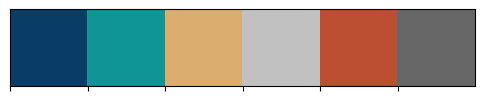

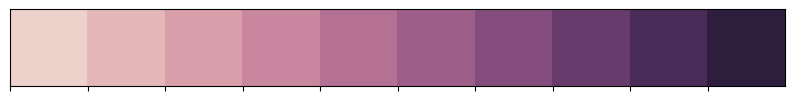

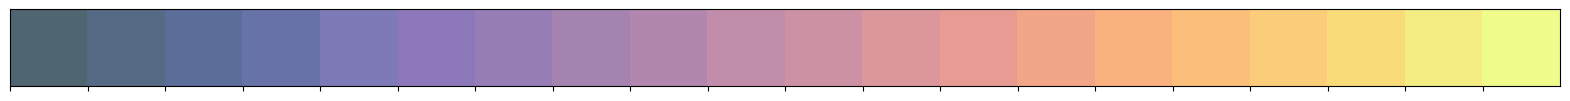

In [2]:
hex_colors = ['#093c66', '#0f9596', '#dbad6e', '#c1c1c1','#bc4e32', '#676767']
discrete_pal = sns.color_palette(hex_colors)
sns.palplot(discrete_pal)

tmp = sns.cubehelix_palette(10)
hex_colors = [matplotlib.colors.rgb2hex(color) for color in tmp]
sequential_pal = sns.color_palette(hex_colors)
sns.palplot(sequential_pal)

discrete_states_cols = ["#4F6570", "#556A85", "#5A6E99", "#6672A8", "#7E79B7",
                        "#8B77BA", "#977DB6","#A583B1", "#B187AE","#C18DAA", 
                        "#CD91A4","#DB979B", "#E89B93","#F1A688","#F9B17E",
                        "#FBBE7B","#FBCC7A","#FADB7C","#F4EC85","#EFFC8C"]
discrete_states = sns.color_palette(discrete_states_cols)
sns.palplot(discrete_states)

# Helper Functions

In [3]:
class KoopmanWeightedTICA:
    def __init__(self, var_cutoff=0.80, lagtime=1):
        self.var_cutoff = var_cutoff
        self.lagtime = lagtime
        self.tica = dt.decomposition.TICA(var_cutoff=self.var_cutoff, lagtime=self.lagtime)
        self.koopman_estimator = dt.covariance.KoopmanWeightingEstimator(lagtime=self.lagtime)

    def fit(self, data):
        # Learning Koopman weights
        reweighting_model = self.koopman_estimator.fit(data).fetch_model()

        # Fitting weights to TICA estimator
        self.tica_reweighted = self.tica.fit(data, weights=reweighting_model)

        # Fetching the TICA model
        self.model = self.tica_reweighted.fit(data).fetch_model()

        # Transforming data using the trained model
        self.tica_output = self.model.transform(data)

    def get_model(self):
        return self.model

    def get_tica_output(self):
        return self.tica_output

def discretize(tica_arr, k):
    """perform kmeans clustering to obtain discrete trajectories"""
    tica_output = [tica_arr[i] for i in range(tica_arr.shape[0])]

    # stride the concatenated data for fitting
    data_concat = np.concatenate(tica_output)
    data_strided = data_concat[::50]

    cluster = KMeans(n_clusters=k, max_iter=50, fixed_seed=1).fit(data_strided).fetch_model()

    dtrajs = [cluster.transform(traj) for traj in tica_output]

    return dtrajs

def estimate_msm(dtrajs, lag_msm=200):
    """estimate msm from discrete trajectories"""
    msm = dt.markov.msm.MaximumLikelihoodMSM(lagtime=lag_msm).fit(dtrajs).fetch_model()
    
    return msm

def estimate_energy(tica_arr, msm, dtrajs, icx=1, icy=2):
    """compute energy landscape"""
    # TICA
    tica_output = [tica_arr[i].tolist() for i in range(tica_arr.shape[0])]
    tica_concatenated = np.concatenate(tica_output)
    
    weights = msm.compute_trajectory_weights(np.concatenate(dtrajs))[0]

    # energy landscape
    # boltzmann constant = 8.314 J/(K*mol), T=303.15K
    energies = dt.util.energy2d(x=tica_concatenated.T[(icx-1)], y=tica_concatenated.T[(icy-1)], bins=100, kbt=2.52, weights=weights)
    
    return energies


def reindex_matrix(mat, idx):
    """reindex matrix based on indices in idx"""
    mat = mat[idx,:]; mat = mat[:, idx]
    return mat

def histogram2d_from_xy(x: np.ndarray, y: np.ndarray, bins=100, weights=None, density=True):
    hist, x_edges, y_edges = np.histogram2d(x, y, bins=bins, weights=weights)
    x_meshgrid = 0.5 * (x_edges[:-1] + x_edges[1:])
    y_meshgrid = 0.5 * (y_edges[:-1] + y_edges[1:])

    if density:
        hist /= np.sum(hist)
    return x_meshgrid, y_meshgrid, hist.T

def energy2d(x: np.ndarray, y: np.ndarray, bins=100, kbt: float = 1., weights=None, shift_energy=True):

    x_meshgrid, y_meshgrid, hist = histogram2d_from_xy(x, y, bins=bins, weights=weights)
    energy = np.full_like(hist, fill_value=np.inf)

    nonzero = hist.nonzero()
    energy[nonzero] = -np.log(hist[nonzero])
    if shift_energy:
        energy[nonzero] -= np.min(energy[nonzero])

    energy *= kbt
    return x_meshgrid, y_meshgrid, energy

In [4]:
def plot_adjust_settings(xlabel, ylabel, ax=None):
    if ax is None:
        ax = plt.gca()
        
    ax.set_xlabel(xlabel,fontsize=11,labelpad=5)
    ax.set_ylabel(ylabel,fontsize=11,labelpad=5)
    ax.tick_params(labelsize=9, pad=5)

# Build MSM

## Energy landscape

In [5]:
src_dir = '/Volumes/LaCie/251209_msm_GHSR-miniG_A204E'
dst_dir = 'mutation'   # relative to this notebook's folder

files = glob.glob(f'{src_dir}/mask*')
print(f"{len(files)} files to copy")
for f in files:
    shutil.copy(f, dst_dir)
    print("copied", os.path.basename(f))

files = glob.glob(f'{src_dir}/distances_data*')
print(f"{len(files)} files to copy")
for f in files:
    shutil.copy(f, dst_dir)
    print("copied", os.path.basename(f))

files = glob.glob(f'{src_dir}/TICA_distances_20_ns*')
print(f"{len(files)} files to copy")
for f in files:
    shutil.copy(f, dst_dir)
    print("copied", os.path.basename(f))

2 files to copy
copied mask_v1.npy
copied mask_v2.npy
5 files to copy
copied distances_data.npy
copied distances_data_filtered_v0.npy
copied distances_data_filtered_v1.npy
copied distances_data_filtered_v2.npy
copied distances_data_filtered.npy
5 files to copy
copied TICA_distances_20_ns_filtered_v0.npy
copied TICA_distances_20_ns_filtered_v1.npy
copied TICA_distances_20_ns_filtered_v2.npy
copied TICA_distances_20_ns.npy
copied TICA_distances_20_ns_filtered.npy


apo (432, 1000, 2)
apo -> (5588, 4)


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"


agonist (780, 1000, 2)
agonist -> (6183, 4)
mutation (290, 1000, 2)
mutation -> (5857, 4)


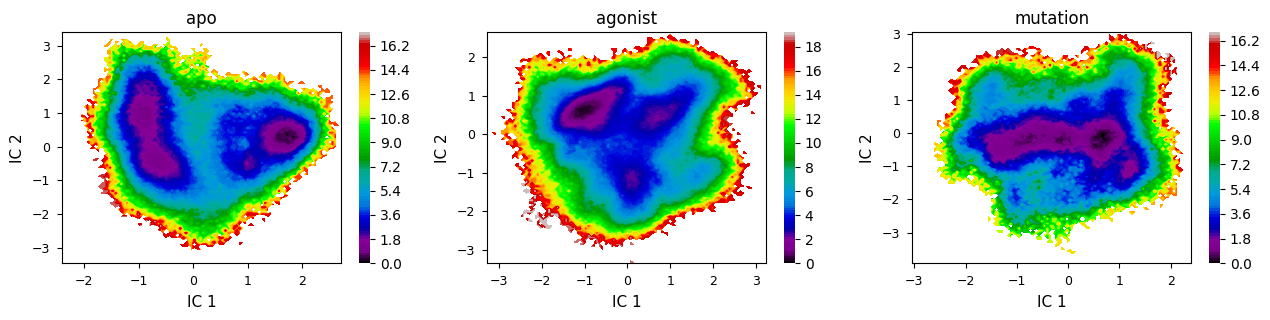

In [67]:
tica_lag = 20
systems = ['apo', 'agonist', 'mutation']

fig, axes = plt.subplots(1, 3, figsize=(4.3*3, 3.3), tight_layout=False)

for ax, system in zip(axes, systems):

    # --- estimate MSM on the filtered TICA (first 2 ICs) ---
    tica_arr = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:, :, :2]
    print(system, tica_arr.shape)
    tica_concatenated = np.concatenate(tica_arr)

    dtrajs = discretize(tica_arr, k=100)
    msm = estimate_msm(dtrajs, lag_msm=200)
    weights = msm.compute_trajectory_weights(np.concatenate(dtrajs))[0]

    # --- IC1/IC2 energy landscape for the figure ---
    xm, ym, energy = energy2d(x=tica_concatenated.T[0], y=tica_concatenated.T[1],
                              bins=100, kbt=2.52, weights=weights)
    energies = dt.util.EnergyLandscape2d(xm, ym, energy, kbt=2.52)
    dt.plots.plot_energy2d(energies, ax=ax, levels=100,
                           contourf_kws=dict(cmap='nipy_spectral'),
                           cbar=True, cbar_kws=None, cbar_ax=None)
    plot_adjust_settings('IC 1', 'IC 2', ax=ax)
    ax.set_title(system)
    ax.legend([], [], frameon=False)

    # --- per-bin energies (IC1 vs IC2 only) ---
    ic_cols = [f"IC{i+1}" for i in range(tica_concatenated.shape[1])]
    df_all = []

    i = 0            # IC1 index
    last_ic = 2      # only the first 2 ICs
    for j in range(1, last_ic):
        x, y = tica_concatenated[:, i], tica_concatenated[:, j]
        xm, ym, e = energy2d(x=x, y=y, bins=100, kbt=2.52, weights=weights)

        X, Y = np.meshgrid(xm, ym)
        mask = np.isfinite(e)
        df = pd.DataFrame({
            ic_cols[i]: X[mask],
            ic_cols[j]: Y[mask],
            f"energy_{j}": e[mask],
        })
        df_all.append(df)

    df_final = df_all[0].sort_values(by='energy_1')

    # merge loop is a no-op with a single IC pair, kept for symmetry
    for cnt, df in enumerate(df_all[1:]):
        df = df[df[f'energy_{cnt+2}'] < 1]
        df_final = pd.merge(df_final, df, on='IC1')

    energy_cols = [f'energy_{k}' for k in range(1, last_ic)]   # -> ['energy_1']
    df_final['energy'] = df_final[energy_cols].mean(axis=1, skipna=True)
    
    df_final.to_pickle(f"{system}/per-bin-energies.pkl")
    print(system, "->", df_final.shape)

plt.show()

## Implied timescales

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"


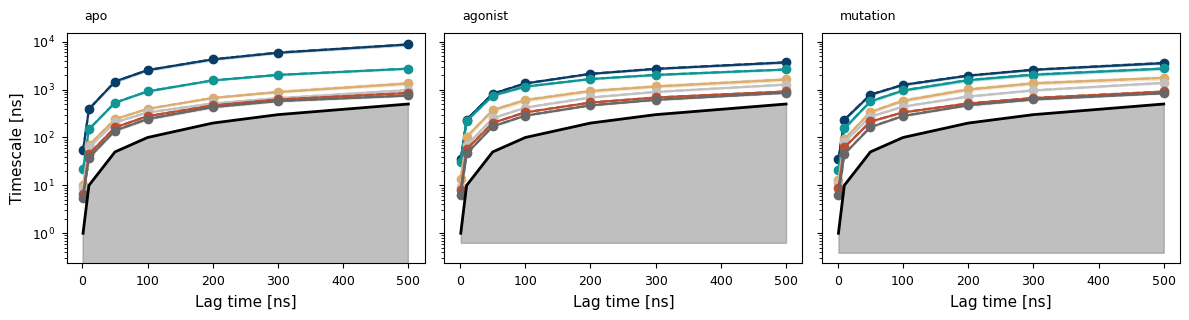

In [7]:
tica_lag = 20
systems = ['apo', 'agonist', 'mutation']

fig, axes = plt.subplots(1, 3, figsize=(4*3,3.3), tight_layout=False, sharey =True, sharex=True)

for cnt, system in enumerate(systems):
    ax = axes[cnt]
    
    # estimate markov state model
    tica_arr = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:, :, :2]
        
    dtrajs = discretize(tica_arr, k=100) # discretize
    msm = estimate_msm(dtrajs, lag_msm=200) # estimate msm

    # implied timescales
    models = []
    lagtimes = [1,10,50,100,200,300, 500]

    for lagtime in lagtimes:
        counts = dt.markov.TransitionCountEstimator(lagtime=lagtime, count_mode='effective').fit_fetch(dtrajs)
        models.append(dt.markov.msm.BayesianMSM().fit_fetch(counts))

    its_data = dt.util.validation.implied_timescales(models)

    dt.plots.plot_implied_timescales(its_data, n_its=6, colors = discrete_pal, ax=ax)

    ax.set_yscale('log')
    if cnt == 0:
        plot_adjust_settings('Lag time [ns]', 'Timescale [ns]', ax=ax)
    else:
        plot_adjust_settings('Lag time [ns]', '', ax=ax)

    ax.text(0.05, 1.1, system, transform=ax.transAxes, fontsize=9, va='top')


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"


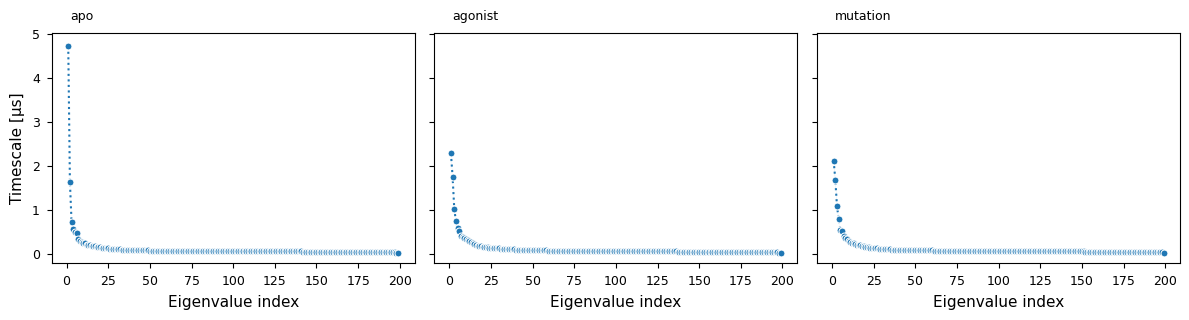

In [8]:
tica_lag = 20
systems = ['apo', 'agonist', 'mutation']

fig, axes = plt.subplots(1, 3, figsize=(4*3,3.3), tight_layout=False, sharey =True, sharex=True)

for cnt, system in enumerate(systems):
    ax = axes[cnt]
    tica_arr = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:, :, :2]
          
    tica_output = [tica_arr[i].tolist() for i in range(tica_arr.shape[0])]

    # Discretization: kmeans clustering
    data_concat = np.concatenate(tica_output)
    data_strided = data_concat[::50]

    cluster = KMeans(n_clusters=200, max_iter=50, fixed_seed=1).fit(data_strided).fetch_model()
    dtrajs = [cluster.transform(np.array(traj)) for traj in tica_output]

    # Bayesian MSM + timescales (each frame = 1 ns)
    msm = dt.markov.msm.BayesianMSM(lagtime=200).fit(dtrajs).fetch_model()

    timescales_samples = np.array([s.timescales() for s in msm.samples])  # (n_samples, n_ts)
    ts_mean = timescales_samples.mean(axis=0) / 1000   # ns -> µs
    ts_std  = timescales_samples.std(axis=0)  / 1000

    df = pd.DataFrame({'timescale': ts_mean, 'err': ts_std,
                    'idx': np.arange(1, len(ts_mean) + 1)})

    sns.lineplot(x="idx", y="timescale", data=df, marker='o', ax=ax, markersize=5, linestyle=':')
    ax.fill_between(df['idx'], df['timescale'] - df['err'], df['timescale'] + df['err'], alpha=0.3)

    if cnt == 0:
        plot_adjust_settings('Eigenvalue index', 'Timescale [µs]', ax=ax)
    else:
        plot_adjust_settings('Eigenvalue index', '', ax=ax)

    ax.text(0.05, 1.1, system, transform=ax.transAxes, fontsize=9, va='top')

# Macrostates

## PCCA

In [68]:
# TICA
tica_lag = 20

systems = {'apo' : 2, 
           'agonist': 1, 
           'mutation': 1}


for system, nstates in systems.items():
    arr = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:,:,:2]
    tica_output = [arr[i] for i in range(arr.shape[0])]

    # Discretization
    data_concat = np.concatenate(tica_output)
    data_strided = data_concat[::50]
    cluster = KMeans(n_clusters=100, max_iter=50, fixed_seed=1).fit(data_strided).fetch_model()
    dtrajs = [cluster.transform(traj) for traj in tica_output]

    # Bayesian MSM
    lag_msm = 200
    msm = dt.markov.msm.BayesianMSM(lagtime=lag_msm, n_samples=100).fit(dtrajs).fetch_model()

    # Map dtrajs to connected-set indices (-1 for unconnected states)
    state_symbols = msm.prior.count_model.state_symbols
    symbol_to_idx = {s: i for i, s in enumerate(state_symbols)}
    connected = [np.array([symbol_to_idx.get(int(s), -1) for s in dtraj]) for dtraj in dtrajs]

    # Filter out trajectories with unconnected frames
    dtrajs_filtered = []
    tica_output_filtered = []
    excluded_count = 0

    for cnt, tmp_arr in enumerate(connected):
        if np.any(tmp_arr == -1):
            excluded_count += 1
        else:
            dtrajs_filtered.append(tmp_arr)
            tica_output_filtered.append(tica_output[cnt])

    print("unconnected trajectories:", excluded_count)

    # ===================
    # PCCA
    pcca = msm.prior.pcca(nstates)

    # Stationary distribution mean + confidence from Bayesian samples
    pi_samples = np.array([s.stationary_distribution for s in msm.samples])  # (n_samples, n_microstates)

    pi_error = np.zeros(nstates)
    pi_mean = np.zeros(nstates)

    for i in range(nstates):
        micro_states = pcca.sets[i]
        pi_per_sample = pi_samples[:, micro_states].sum(axis=1)
        pi_mean[i] = pi_per_sample.mean()
        l = np.percentile(pi_per_sample, 2.5)
        r = np.percentile(pi_per_sample, 97.5)
        pi_error[i] = (r - l) / 2

    df1 = pd.DataFrame()
    df1['tmp'] = np.arange(nstates)
    df1['pi'] = pi_mean
    df1['pi_error'] = pi_error
    df1["G/kT"] = -np.log(df1["pi"])
    df1 = df1.sort_values(by='pi', ascending=False)
    df1['State'] = np.arange(nstates) + 1
    df1.to_pickle(f"{system}/Bayesian_MSM_macrostates.pkl")

    tica_concatenated = np.concatenate(np.array(tica_output_filtered))
    df2 = pd.DataFrame(tica_concatenated, columns=["IC%d" % x for x in range(1, arr.shape[2]+1)])
    df2["tmp"] = pcca.assignments[np.concatenate(dtrajs_filtered)]
    memberships = pcca.memberships[np.concatenate(dtrajs_filtered)]
    df2["membership"] = np.max(memberships, axis=1)

    df = pd.merge(df1, df2, on="tmp")
    df.to_pickle(f"{system}/Bayesian_MSM.pkl")

    df_out = df[["State", "pi", "pi_error"]].drop_duplicates().sort_values(by="State")
    print(df_out)

    # ===================
    # microstates
    df_micro = pd.DataFrame()
    for ic in range(arr.shape[2]):
        df_micro["IC%d" % (ic+1)] = cluster.cluster_centers[:, ic]

    # filter rows of connected set
    tmp = pd.DataFrame()
    tmp['dtrajs'] = np.concatenate(dtrajs)
    tmp['dtrajs_connected'] = np.concatenate(connected)

    tmp = tmp[tmp['dtrajs_connected'] == -1]
    remove_rows = np.unique(tmp['dtrajs'])

    df_micro = df_micro.drop(index=remove_rows)

    df_micro["pi_micro"] = msm.prior.stationary_distribution
    df_micro["tmp"] = pcca.assignments
    df_micro["membership"] = np.max(pcca.memberships, axis=1)
    df_micro["microstate"] = np.arange(len(df_micro))
    df_micro.to_pickle(f"{system}/Bayesian_MSM_microstates.pkl")

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"


unconnected trajectories: 0
        State        pi  pi_error
0           1  0.558997  0.022978
277694      2  0.441003  0.022978
unconnected trajectories: 0
   State   pi      pi_error
0      1  1.0  4.440892e-16
unconnected trajectories: 0
   State   pi      pi_error
0      1  1.0  4.996004e-16


## Energy macrostates

(432, 1000, 2)


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"


(780, 1000, 2)
(290, 1000, 2)


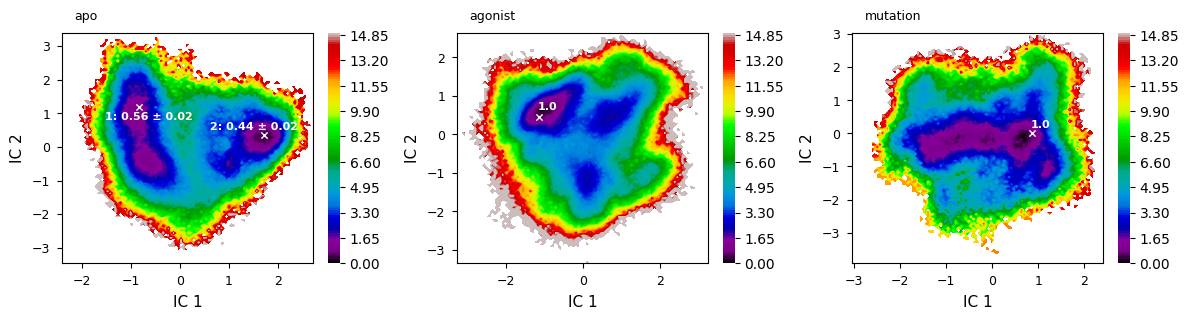

In [69]:
systems = ['apo', 'agonist', 'mutation']

fig, axes = plt.subplots(1, 3, figsize=(4*3,3.3), tight_layout=False)
for cnt, system in enumerate(systems):
    ax = axes[cnt]

    ### plot landscape ###
    # estimate markov state model
    tica_arr = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:,:,:2]  # tica
    print(tica_arr.shape)
    tica_concatenated = np.concatenate(tica_arr)
    dtrajs = discretize(tica_arr, k=100) # discretize
    msm = estimate_msm(dtrajs, lag_msm=200) # estimate msm

    # energy landscape
    weights = msm.compute_trajectory_weights(np.concatenate(dtrajs))[0]
    x_meshgrid, y_meshgrid, energy = energy2d(x=tica_concatenated.T[0], y=tica_concatenated.T[1], bins=100, kbt=2.52, weights=weights)
    energy[np.isinf(energy)] = np.nan
    energy[energy > 15] = 15
    energies = dt.util.EnergyLandscape2d(x_meshgrid, y_meshgrid, energy, kbt=2.52)
    dt.plots.plot_energy2d(energies, ax=ax, levels=100, contourf_kws=dict(cmap='nipy_spectral'), cbar=True, cbar_kws=None, cbar_ax=None)

    ### plot state labels ###
    # macrostate labels (print microstate with highest membership to macrostate)
    df_micro = pd.read_pickle(f"{system}/Bayesian_MSM_microstates.pkl")
    df_macro = pd.read_pickle(f"{system}/Bayesian_MSM_macrostates.pkl")
    df_merged = pd.merge(df_micro, df_macro, on="tmp")

    idx = df_merged.groupby('State')['pi_micro'].idxmax()
    df_merged = df_merged.loc[idx]
    df_merged = df_merged.reset_index(drop=True)
    sns.scatterplot(data=df_merged, x="IC1", y="IC2", marker="x", color = "white", linewidth=1, ax = ax, s=20)

    offsets = [[(0.2, -0.3), (-0.2, 0.25)], [(0.2 , 0.25)], [(0.2 , 0.25)]]

    texts = []
    for j, row in df_merged.iterrows():
        x = row["IC1"]+ offsets[cnt][j][0]
        y = row["IC2"]+ offsets[cnt][j][1]
        pi = row["pi"]
        label = f"{pi:.1f}" if pi == 1.0 else f"{int(row['State'])}: {pi:.2f} ± {row['pi_error']:.2f}"
        #label = f"{pi:.1f}" if pi == 1.0 else f"{int(row['State'])}: {pi:.2f}"
        texts.append(ax.text(x, y, label, ha='center', va='center', fontsize=8, fontweight='bold', color='white'))

    ax.legend([],[], frameon=False)
    plot_adjust_settings('IC 1', 'IC 2', ax=ax)
    ax.text(0.05, 1.1, system, transform=ax.transAxes, fontsize=9, va='top')



# Extract structures

In [70]:
# annotate tica data — all three systems
setting = "two-state"
tica_lag = 20

classes = {"agonist": ['M0', 'U0', 'U1', 'V2', 'V3', 'V4'],
           "apo":     ['M0', 'U0', 'U1', 'V2'],
           "mutation":['M0', 'U0', 'U1']}

src_root = "/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features"   

for system, topdirs in classes.items():
    arr = np.load(f"{system}/TICA_distances_{tica_lag}_ns.npy")[:, :, :5]
    tica_output = [arr[i].tolist() for i in range(arr.shape[0])]
    print(system, np.shape(tica_output))

    counter = 0
    lst = []
    for i, tmp in enumerate(topdirs):
        topdir = f"{src_root}/{system}/{tmp}"

        if not os.path.isdir(topdir):
            raise FileNotFoundError(f"missing source dir: {topdir}")

        subdirs_int = None
        for dir_path, sub_dirs, fichers in os.walk(topdir):
            subdirs_int = sorted(int(x) for x in sub_dirs if len(x) <= 2)
            break
        if not subdirs_int:
            raise RuntimeError(f"no starting-point subdirs found in {topdir}")

        for starting_point in subdirs_int:
            for rep in range(4):
                arr = tica_output[counter]
                new_arr = np.insert(arr,     0, np.full((1000,), i),              axis=1)
                new_arr = np.insert(new_arr, 1, np.full((1000,), starting_point), axis=1)
                new_arr = np.insert(new_arr, 2, np.full((1000,), rep),            axis=1)
                new_arr = np.insert(new_arr, 3, np.arange(1000),                  axis=1)
                lst.append(new_arr)
                counter += 1

    tmp = np.array(lst)
    print(system, tmp.shape)

    masks = sorted(glob.glob(f'{system}/mask_v?.npy'))
    for mask in masks:
        mask = np.load(mask)
        tmp = tmp[~mask]

    tmp = tmp[:, :, :4]
    arr = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:, :, :2]
    result = np.concatenate((tmp, arr), axis=2)
    arr_anno = np.concatenate(result)

    cols = ['N', 'starting_point', 'rep', 'time'] + [f"IC{x+1}" for x in range(2)]
    df_anno = pd.DataFrame(arr_anno, columns=cols)

    df = pd.read_pickle(f"{system}/Bayesian_MSM.pkl")
    
    merged_df = pd.merge(df, df_anno, on=[f"IC{x+1}" for x in range(2)], how="inner")
    merged_df.to_pickle(f"{system}/Bayesian_MSM_anno_{setting}.pkl")
    print(system, "->", merged_df.shape)

agonist (780, 1000, 5)
agonist (780, 1000, 9)
agonist -> (780000, 12)
apo (432, 1000, 5)
apo (432, 1000, 9)
apo -> (432000, 12)
mutation (292, 1000, 5)
mutation (292, 1000, 9)
mutation -> (290000, 12)


In [6]:
setting = 'two-state'

classes = {"agonist": ['M0', 'U0', 'U1', 'V2', 'V3', 'V4'],
           "apo":     ['M0', 'U0', 'U1', 'V2'],
           "mutation":['M0', 'U0', 'U1']}


src_root = "/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features"
ics = ['IC1', 'IC2']

for system, subdirs in classes.items():

    src_dir = f"{src_root}/{system}"

    out_root = f"{system}/macrostates_frames"
    if os.path.exists(out_root):
        for root, dirs, files in os.walk(out_root, topdown=False):
            for f in files:
                if f != '7f9y-align.pdb':
                    os.remove(os.path.join(root, f))
            for d in dirs:
                dirpath = os.path.join(root, d)
                if not os.listdir(dirpath):
                    os.rmdir(dirpath)

    df = pd.read_pickle(f"{system}/Bayesian_MSM_anno_{setting}.pkl")
    per_bin_energies = pd.read_pickle(f"{system}/per-bin-energies.pkl")[ics + ['energy']]
    print(len(df))
    print(len(per_bin_energies))
    tree = cKDTree(df[ics].values)
    distances, indices = tree.query(per_bin_energies[ics].values)

    closest_rows = df.iloc[indices].reset_index(drop=True)
    closest_rows["frame_energy"] = per_bin_energies["energy"].values
    if system == "mutation":
        closest_rows = closest_rows[closest_rows['IC1'] > 0.2]

    lst = []
    for state in np.unique(closest_rows['State'].values):
        tmp = closest_rows[closest_rows['State'] == state]
        tmp = tmp.sort_values(by='frame_energy').head(50).reset_index()

        lst.append(tmp)

        topdir_new = f"{out_root}/{state}"
        os.makedirs(topdir_new, exist_ok=True)

        for idx, row in tmp.iterrows():
            dir_old = f"{src_dir}/{subdirs[int(row['N'])]}/{int(row['starting_point'])}/{int(row['rep'])}"
            print(dir_old)

            if os.path.exists(f"{dir_old}/protein-pbc.xtc"):
                u = mda.Universe(f"{dir_old}/protein.gro", f"{dir_old}/protein-pbc.xtc")
                u.trajectory[int(row["time"] * 5)]

                u.add_TopologyAttr("chainID")
                u.atoms[:4877].chainIDs = "A"
                u.atoms[4877:8577].chainIDs = "B"

                sel = u.select_atoms('all')
                sel.write(f"{topdir_new}/{state:02}_{idx:04d}_{system}.pdb")

    tmp = pd.concat(lst)
    tmp.to_pickle(f"{system}/extracted-frames.pkl")
    print(system, "->", tmp.shape)

780000
6183
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V2/31/3


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'altLocs' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'icodes' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'occupancies' Using default value of '1.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'tempfactors' Using default value of '0.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'elements' Using default value of ' '
  warnings

/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V2/36/3
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V2/31/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V2/35/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V2/36/3
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V2/27/2
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V2/36/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V3/36/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V3/36/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V3/37/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/U0/46/2
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/M0/20/3
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V3/46/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V3/40/2
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/agonist/V3/20/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_featu

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'altLocs' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'icodes' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'occupancies' Using default value of '1.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'tempfactors' Using default value of '0.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'elements' Using default value of ' '
  warnings

/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/M0/21/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/V2/44/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/U0/35/3
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/M0/1/2
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/V2/22/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/M0/39/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/V2/44/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/U0/37/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/M0/75/3
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/M0/83/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/V2/27/2
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/M0/83/2
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/V2/47/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/V2/47/2
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/apo/U0/37/2
/Volumes/LaCie/260110_msm_GHSR+miniG_smar

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'altLocs' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'icodes' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'occupancies' Using default value of '1.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'tempfactors' Using default value of '0.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'elements' Using default value of ' '
  warnings

/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/U0/12/3
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/U0/26/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/U0/21/2
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/M0/32/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/M0/43/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/U0/18/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/U1/16/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/M0/0/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/U0/12/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/M0/0/1
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/U0/18/0
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/M0/0/2
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/U0/21/2
/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features/mutation/U1/3/0
/Volumes/LaCie/260110_msm_GHSR+miniG_s

# Projections

## Input space

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"


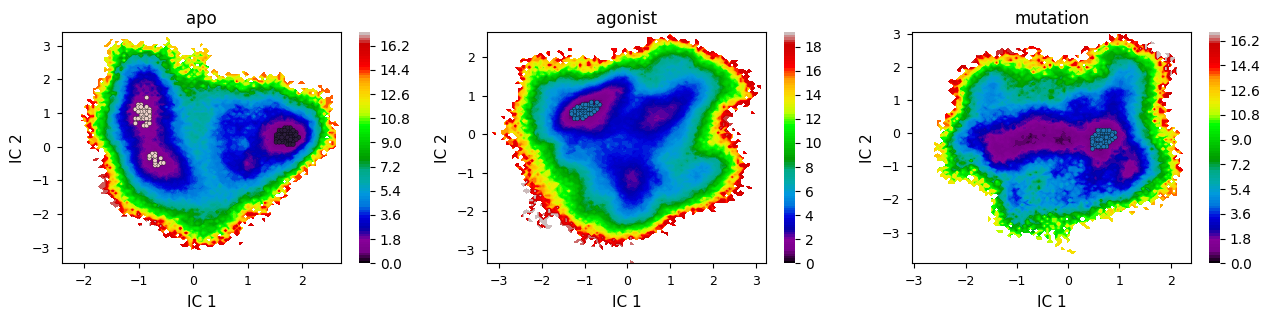

In [7]:
tica_lag = 20
systems = ['apo', 'agonist', 'mutation']

fig, axes = plt.subplots(1, 3, figsize=(4.3*3, 3.3), tight_layout=False)

for ax, system in zip(axes, systems):

    # estimate MSM
    tica_arr = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:, :, :2]
    dtrajs = discretize(tica_arr, k=100)
    msm = estimate_msm(dtrajs, lag_msm=200)

    # energy landscape
    energies = estimate_energy(tica_arr, msm, dtrajs)
    dt.plots.plot_energy2d(energies, ax=ax, levels=100,
                           contourf_kws=dict(cmap='nipy_spectral'),
                           cbar=True, cbar_kws=None, cbar_ax=None)
    plot_adjust_settings('IC 1', 'IC 2', ax=ax)
    ax.set_title(system)
    ax.legend([], [], frameon=False)

    # low-energy frames
    tmp = pd.read_pickle(f"{system}/extracted-frames.pkl")
    sns.scatterplot(tmp, x='IC1', y='IC2', hue='State', ax=ax,
                    s=10, edgecolor='black', legend=False)

plt.show()

In [8]:
systems = ['apo', 'agonist', 'mutation']

for system in systems:

    state_dirs = sorted(glob.glob(f"{system}/macrostates_frames/*"))

    for topdir in state_dirs:
        files = sorted(glob.glob(f"{topdir}/??_????_{system}.pdb"))
        if not files:
            print("no frames in", topdir)
            continue

        u = mda.Universe(files[0], files)
        ref = mda.Universe(files[0])

        sel = u.select_atoms('all')
        sel.write(f"{topdir}/macrostates.pdb")

        align.AlignTraj(
            u,
            ref,
            select='name CA',
            filename=f"{topdir}/macrostates.xtc",
        ).run()

        print("wrote", f"{topdir}/macrostates.{{pdb,xtc}}")

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/topology/PDBParser.py:376: UserWarning: Element information is missing, elements attribute will not be populated. If needed these can be guessed using universe.guess_TopologyAttrs(context='default', to_guess=['elements']).
  warnings.warn("Element information is missing, elements attribute "
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/base.py:730: UserWarning: Reader has no dt information, set to 1.0 ps
  return self.ts.dt
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'elements' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.

wrote apo/macrostates_frames/1/macrostates.{pdb,xtc}
wrote apo/macrostates_frames/2/macrostates.{pdb,xtc}
wrote agonist/macrostates_frames/1/macrostates.{pdb,xtc}
wrote mutation/macrostates_frames/1/macrostates.{pdb,xtc}
no frames in mutation/macrostates_frames/2


In [9]:
tica_lag = 20

systems = {'apo' : 2, 
           'agonist': 1, 
           'mutation': 1}

for system, nstates in systems.items():
    data = np.load(f"{system}/distances_data_filtered.npy")
    model = KoopmanWeightedTICA(var_cutoff=0.80, lagtime=tica_lag)
    model.fit(data)

    src_dir = f"{system}/macrostates_frames"
    
    if system == 'mutation':
        pairs = [(2211, 546), (2211, 3576), (2211, 4670), (2211, 6316), (2211, 6524), (2211, 6873), (2211, 7694), (253, 8168), (253, 8293), (253, 8513), (1548, 8168), (1548, 8293), (1548, 8513), (2211, 8168), (2211, 8293), (2211, 8513), (3055, 8168), (3055, 8293), (3055, 8513), (3908, 8168), (3908, 8293), (3908, 8513), (4459, 8168), (4459, 8293), (4459, 8513)]
    else:
        pairs = [(2211, 546), (2211, 3571), (2211, 4665), (2211, 6311), (2211, 6519), (2211, 6868), (2211, 7689), (253, 8163), (253, 8288), (253, 8508), (1548, 8163), (1548, 8288), (1548, 8508), (2211, 8163), (2211, 8288), (2211, 8508), (3050, 8163), (3050, 8288), (3050, 8508), (3903, 8163), (3903, 8288), (3903, 8508), (4454, 8163), (4454, 8288), (4454, 8508)]

    
    idx1 = np.array([p[0] for p in pairs])
    idx2 = np.array([p[1] for p in pairs])

    lst = []
    for i in range(nstates):
        topdir = f"{src_dir}/{i+1}"

        u = mda.Universe(f'{topdir}/macrostates.pdb', f'{topdir}/macrostates.xtc')

        feat_data = []
        for ts in u.trajectory:
            pos1 = u.atoms[idx1].positions
            pos2 = u.atoms[idx2].positions
            dists = np.linalg.norm(pos1 - pos2, axis=1) / 10.0  # Å → nm
            feat_data.append(dists)

        data = np.array(feat_data)

        tica_output = model.get_model().transform(data)

        df = pd.DataFrame(tica_output[:, :2], columns=['IC%d' % (j+1) for j in range(2)])
        df['state'] = i + 1
        lst.append(df)

    df = pd.concat(lst)
    df.to_pickle(f'{system}/TICA_macrostates_input_space.pkl')


(432, 1000, 2)


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"


(780, 1000, 2)
(290, 1000, 2)


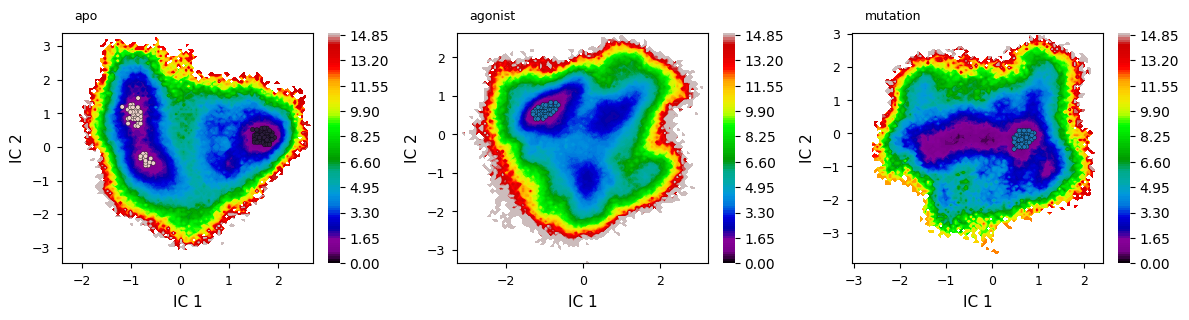

In [10]:
systems = ['apo', 'agonist', 'mutation']

fig, axes = plt.subplots(1, 3, figsize=(4*3,3.3), tight_layout=False)

for cnt, system in enumerate(systems):
    ax = axes[cnt]

    ### plot landscape ###
    # estimate markov state model
    tica_arr = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:,:,:2]  # tica
    print(tica_arr.shape)
    tica_concatenated = np.concatenate(tica_arr)
    dtrajs = discretize(tica_arr, k=100) # discretize
    msm = estimate_msm(dtrajs, lag_msm=200) # estimate msm

    # energy landscape
    weights = msm.compute_trajectory_weights(np.concatenate(dtrajs))[0]
    x_meshgrid, y_meshgrid, energy = energy2d(x=tica_concatenated.T[0], y=tica_concatenated.T[1], bins=100, kbt=2.52, weights=weights)
    energy[np.isinf(energy)] = np.nan
    energy[energy > 15] = 15
    energies = dt.util.EnergyLandscape2d(x_meshgrid, y_meshgrid, energy, kbt=2.52)
    dt.plots.plot_energy2d(energies, ax=ax, levels=100, contourf_kws=dict(cmap='nipy_spectral'), cbar=True, cbar_kws=None, cbar_ax=None)

    ### plot low energy frames ###
    tmp = pd.read_pickle(f'{system}/TICA_macrostates_input_space.pkl')
    sns.scatterplot(tmp, x='IC1', y='IC2', hue='state', ax=ax, s=10, edgecolor='black', legend=False)

    ax.legend([],[], frameon=False)
    plot_adjust_settings('IC 1', 'IC 2', ax=ax)
    ax.text(0.05, 1.1, system, transform=ax.transAxes, fontsize=9, va='top')


## Apo space

In [11]:
tica_lag = 20

# number of macrostates to project per system
systems = {'agonist': 1, 'mutation': 1}

# construct apo space
data = np.load(f"apo/distances_data_filtered.npy")
model = KoopmanWeightedTICA(var_cutoff=0.80, lagtime=tica_lag)
model.fit(data)

lst = []
for system, nstates in systems.items():
    src_dir = f"{system}/macrostates_frames"

    if system == 'mutation':
        pairs = [(2211, 546), (2211, 3576), (2211, 4670), (2211, 6316), (2211, 6524), (2211, 6873), (2211, 7694), (253, 8168), (253, 8293), (253, 8513), (1548, 8168), (1548, 8293), (1548, 8513), (2211, 8168), (2211, 8293), (2211, 8513), (3055, 8168), (3055, 8293), (3055, 8513), (3908, 8168), (3908, 8293), (3908, 8513), (4459, 8168), (4459, 8293), (4459, 8513)]
    else:
        pairs = [(2211, 546), (2211, 3571), (2211, 4665), (2211, 6311), (2211, 6519), (2211, 6868), (2211, 7689), (253, 8163), (253, 8288), (253, 8508), (1548, 8163), (1548, 8288), (1548, 8508), (2211, 8163), (2211, 8288), (2211, 8508), (3050, 8163), (3050, 8288), (3050, 8508), (3903, 8163), (3903, 8288), (3903, 8508), (4454, 8163), (4454, 8288), (4454, 8508)]

    idx1 = np.array([p[0] for p in pairs])
    idx2 = np.array([p[1] for p in pairs])

    for state in range(1, nstates + 1):
        topdir = f"{src_dir}/{state}"

        u = mda.Universe(f'{topdir}/macrostates.pdb', f'{topdir}/macrostates.xtc')

        feat_data = []
        for ts in u.trajectory:
            pos1 = u.atoms[idx1].positions
            pos2 = u.atoms[idx2].positions
            dists = np.linalg.norm(pos1 - pos2, axis=1) / 10.0  # Å → nm
            feat_data.append(dists)

        data = np.array(feat_data)

        tica_output = model.get_model().transform(data)

        df = pd.DataFrame(tica_output[:, :2], columns=['IC%d' % (j + 1) for j in range(2)])
        df['system'] = system
        df['state'] = state
        lst.append(df)

df = pd.concat(lst)
df.to_pickle(f'TICA_macrostates_apo_space.pkl')

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/topology/PDBParser.py:376: UserWarning: Element information is missing, elements attribute will not be populated. If needed these can be guessed using universe.guess_TopologyAttrs(context='default', to_guess=['elements']).
  warnings.warn("Element information is missing, elements attribute "


(432, 1000, 2)


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"


Text(0.05, 1.1, 'apo')

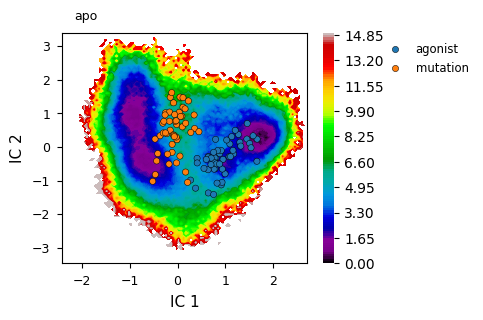

In [12]:
tica_lag = 20

fig, ax = plt.subplots(1, 1, figsize=(4.8,3.3), tight_layout=False)

### plot landscape ###
# estimate markov state model
tica_arr = np.load(f"apo/TICA_distances_{tica_lag}_ns_filtered.npy")[:,:,:2]  # tica
print(tica_arr.shape)
tica_concatenated = np.concatenate(tica_arr)
dtrajs = discretize(tica_arr, k=100) # discretize
msm = estimate_msm(dtrajs, lag_msm=200) # estimate msm

# energy landscape
weights = msm.compute_trajectory_weights(np.concatenate(dtrajs))[0]
x_meshgrid, y_meshgrid, energy = energy2d(x=tica_concatenated.T[0], y=tica_concatenated.T[1], bins=100, kbt=2.52, weights=weights)
energy[np.isinf(energy)] = np.nan
energy[energy > 15] = 15
energies = dt.util.EnergyLandscape2d(x_meshgrid, y_meshgrid, energy, kbt=2.52)
dt.plots.plot_energy2d(energies, ax=ax, levels=100, contourf_kws=dict(cmap='nipy_spectral'), cbar=True, cbar_kws=None, cbar_ax=None)

### plot low energy frames ###
tmp = pd.read_pickle('TICA_macrostates_apo_space.pkl')
sns.scatterplot(tmp, x='IC1', y='IC2', hue='system', ax=ax, s=20, edgecolor='black')

ax.legend(frameon=False, bbox_to_anchor=(1.7,1), fontsize='small')
plot_adjust_settings('IC 1', 'IC 2', ax=ax)
ax.text(0.05, 1.1, 'apo', transform=ax.transAxes, fontsize=9, va='top')

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"


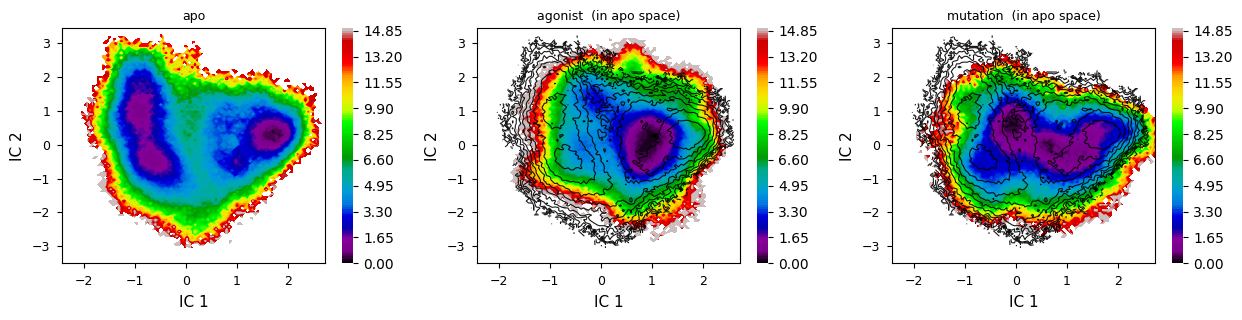

In [13]:
tica_lag = 20
systems = ['agonist', 'mutation']

# ---- 1) fit the apo TICA model = shared projection basis ----
apo_data = np.load("apo/distances_data_filtered.npy")            # (n_traj, 1000, 25)
apo_model = KoopmanWeightedTICA(var_cutoff=0.80, lagtime=tica_lag)
apo_model.fit(apo_data)

# ---- apo reference landscape (its own MSM-reweighted FES in apo coords) ----
apo_tica = np.load(f"apo/TICA_distances_{tica_lag}_ns_filtered.npy")[:, :, :2]
apo_cat  = np.concatenate(apo_tica)
apo_dtrajs = discretize(apo_tica, k=100)
apo_msm    = estimate_msm(apo_dtrajs, lag_msm=200)
apo_w      = apo_msm.compute_trajectory_weights(np.concatenate(apo_dtrajs))[0]
xm0, ym0, e0 = energy2d(x=apo_cat.T[0], y=apo_cat.T[1], bins=100, kbt=2.52, weights=apo_w)
e0[np.isinf(e0)] = np.nan
e0_capped = e0.copy()
e0_capped[e0_capped > 15] = 15

xlim = (apo_cat[:, 0].min(), apo_cat[:, 0].max())
ylim = (apo_cat[:, 1].min(), apo_cat[:, 1].max())

# one extra panel on the left for the apo landscape itself
n_panels = len(systems) + 1
fig, axes = plt.subplots(1, n_panels, figsize=(4.2 * n_panels, 3.3), tight_layout=False)
axes = np.atleast_1d(axes)

# ---- left panel: apo landscape (reference) ----
ax = axes[0]
apo_energies = dt.util.EnergyLandscape2d(xm0, ym0, e0_capped, kbt=2.52)
dt.plots.plot_energy2d(apo_energies, ax=ax, levels=100,
                       contourf_kws=dict(cmap='nipy_spectral'),
                       cbar=True, cbar_kws=None, cbar_ax=None)
ax.set_xlim(xlim); ax.set_ylim(ylim)
plot_adjust_settings('IC 1', 'IC 2', ax=ax)
ax.set_title("apo", fontsize=9)

# ---- remaining panels: agonist / mutation projected into apo space ----
for ax, system in zip(axes[1:], systems):

    # ---- 2) project ALL filtered frames of this system into apo space ----
    dist = np.load(f"{system}/distances_data_filtered.npy")       # (n_traj, 1000, 25)
    n_traj = dist.shape[0]
    dist_cat = np.concatenate([dist[i] for i in range(n_traj)])   # traj-order concat -> (N, 25)
    apo_ic = apo_model.get_model().transform(dist_cat)[:, :2]     # apo IC1/IC2 per frame

    # ---- 3) equilibrium weights from THIS system's own MSM (in its own space) ----
    sys_tica = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:, :, :2]
    sys_dtrajs = discretize(sys_tica, k=100)
    sys_msm    = estimate_msm(sys_dtrajs, lag_msm=200)
    weights    = sys_msm.compute_trajectory_weights(np.concatenate(sys_dtrajs))[0]
    assert len(weights) == len(apo_ic), f"{system}: weight/coord mismatch {len(weights)} vs {len(apo_ic)}"

    # ---- 4) reweighted FES on the apo IC1/IC2 grid ----
    xm, ym, energy = energy2d(x=apo_ic[:, 0], y=apo_ic[:, 1], bins=100, kbt=2.52, weights=weights)
    energy[np.isinf(energy)] = np.nan
    energy[energy > 15] = 15
    energies = dt.util.EnergyLandscape2d(xm, ym, energy, kbt=2.52)
    dt.plots.plot_energy2d(energies, ax=ax, levels=100,
                           contourf_kws=dict(cmap='nipy_spectral'),
                           cbar=True, cbar_kws=None, cbar_ax=None)

    # ---- apo landscape as reference contour lines ----
    ax.contour(xm0, ym0, e0, levels=12, colors='black', linewidths=0.8, alpha=0.9)

    # keep a common view so panels are comparable to the apo axes
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    plot_adjust_settings('IC 1', 'IC 2', ax=ax)
    ax.set_title(f"{system}  (in apo space)", fontsize=9)

    # optional: cache projected coords + weights for reuse
    pd.DataFrame({'IC1': apo_ic[:, 0], 'IC2': apo_ic[:, 1], 'weight': weights,
                  'system': system}).to_pickle(f"{system}/FES_apo_space_reweighted.pkl")

plt.show()

# Extract structures after projection into apo space

In [13]:
# --- lowest-energy frames after projection into apo TICA space ---
# Same idea as the original extraction (per-bin energies -> nearest frame -> 50 lowest),
# but every system is described in the apo IC1/IC2 coordinates.
#   apo               : 50 lowest per apo PCCA state (apo 1 / apo 2)
#   agonist           : 50 lowest overall (one group)
#   mutation          : 50 lowest overall among frames with apo IC1 < 0.2 (one group)
#   coordinates : apo TICA (refit = stored apo TICA, checked)
#   energies    : each system's OWN MSM weights, histogrammed on its apo-space projection
#   apo_state   : apo PCCA state of the nearest apo frame in apo IC1/IC2
from scipy.spatial import cKDTree

tica_lag  = 20
n_frames  = 50
out_name  = 'apo_space_frames'
src_root  = "/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features"
classes   = {"apo":      ['M0', 'U0', 'U1', 'V2'],
             "agonist":  ['M0', 'U0', 'U1', 'V2', 'V3', 'V4'],
             "mutation": ['M0', 'U0', 'U1']}
n_rec     = {'apo': 4877, 'agonist': 4877, 'mutation': 4882}   # receptor atoms (A204E: +5)
n_minig   = 3700

# ---- apo TICA model + apo PCCA states (same settings as the PCCA cell) ----
apo_model = KoopmanWeightedTICA(var_cutoff=0.80, lagtime=tica_lag)
apo_model.fit(np.load("apo/distances_data_filtered.npy"))

apo_tica   = np.load(f"apo/TICA_distances_{tica_lag}_ns_filtered.npy")[:, :, :2]
apo_cat    = np.concatenate(apo_tica)
apo_dtrajs = discretize(apo_tica, k=100)
apo_bmsm   = dt.markov.msm.BayesianMSM(lagtime=200, n_samples=100).fit(apo_dtrajs).fetch_model()
apo_pcca   = apo_bmsm.prior.pcca(2)
sym        = {s: i for i, s in enumerate(apo_bmsm.prior.count_model.state_symbols)}
apo_assign = apo_pcca.assignments[[sym[int(s)] for s in np.concatenate(apo_dtrajs)]]
apo_w      = np.concatenate(apo_bmsm.prior.compute_trajectory_weights(apo_dtrajs))
pi_apo     = np.array([apo_w[apo_assign == k].sum() for k in range(2)])
rank       = {k: r + 1 for r, k in enumerate(np.argsort(-pi_apo))}   # State 1 = most populated
apo_state  = np.array([rank[k] for k in apo_assign])
apo_tree   = cKDTree(apo_cat)
print("apo PCCA populations:", {rank[k]: round(pi_apo[k], 2) for k in range(2)})

def frame_keys(system, topdirs):
    """(N, starting_point, rep) per filtered trajectory, same order as the TICA arrays"""
    keys = []
    for i, tmp in enumerate(topdirs):
        subdirs_int = sorted(int(x) for x in next(os.walk(f"{src_root}/{system}/{tmp}"))[1] if len(x) <= 2)
        keys += [(i, j, k) for j in subdirs_int for k in range(4)]
    keys = np.array(keys)
    for mask in sorted(glob.glob(f"{system}/mask_v?.npy")):
        keys = keys[~np.load(mask)]
    return keys

for system, topdirs in classes.items():
    # ---- apo-space coordinates + own MSM weights for every frame ----
    dist = np.load(f"{system}/distances_data_filtered.npy")
    if system == 'apo':
        ic = apo_cat
    else:
        ic = apo_model.get_model().transform(np.concatenate(dist))[:, :2]
    sys_tica   = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:, :, :2]
    sys_dtrajs = discretize(sys_tica, k=100)
    weights    = estimate_msm(sys_dtrajs, lag_msm=200).compute_trajectory_weights(np.concatenate(sys_dtrajs))[0]
    assert len(weights) == len(ic)

    # ---- frame annotation (trajectory directory + frame index) ----
    keys = frame_keys(system, topdirs)
    assert len(keys) == dist.shape[0]
    n_fr = dist.shape[1]
    anno = pd.DataFrame(np.repeat(keys, n_fr, axis=0), columns=['N', 'starting_point', 'rep'])
    anno['time'] = np.tile(np.arange(n_fr), len(keys))
    anno['IC1'], anno['IC2'] = ic[:, 0], ic[:, 1]
    anno['apo_state'] = apo_state if system == 'apo' else apo_state[apo_tree.query(ic)[1]]
    anno['L239_T203'] = np.load(f"{system}/L239_T203_dist_filtered.npy").ravel()

    # ---- per-bin energies in apo space -> nearest frame per bin ----
    xm, ym, e = energy2d(x=ic[:, 0], y=ic[:, 1], bins=100, kbt=2.52, weights=weights)
    X, Y = np.meshgrid(xm, ym); ok = np.isfinite(e)
    bins_df = pd.DataFrame({'IC1': X[ok], 'IC2': Y[ok], 'frame_energy': e[ok]})
    _, nearest = cKDTree(ic).query(bins_df[['IC1', 'IC2']].values)
    picked = anno.iloc[nearest].reset_index(drop=True)
    picked['frame_energy'] = bins_df['frame_energy'].values
    picked = picked.sort_values('frame_energy').drop_duplicates(['N', 'starting_point', 'rep', 'time'])

    # mutation: only frames left of apo IC1 = 0.2 (the apo 1-side minimum in apo space)
    if system == 'mutation':
        picked = picked[picked['IC1'] < 0.2]

    # ---- clean output folder ----
    out_root = f"{system}/{out_name}"
    if os.path.exists(out_root):
        shutil.rmtree(out_root)

    # apo keeps its two PCCA states; agonist / mutation: one group = 50 lowest overall
    groups = {s: picked[picked['apo_state'] == s] for s in (1, 2)} if system == 'apo' else {1: picked}

    lst = []
    for state, grp in groups.items():
        tmp = grp.head(n_frames).reset_index(drop=True)
        tmp['State'] = state
        lst.append(tmp)
        topdir_new = f"{out_root}/{state}"
        os.makedirs(topdir_new, exist_ok=True)
        # reference for the later 7F9Y alignment (same topology as this system's macrostate frames)
        shutil.copy(f"{system}/macrostates_frames/1/7f9y-align.pdb", topdir_new)

        for idx, row in tmp.iterrows():
            dir_old = f"{src_root}/{system}/{topdirs[int(row['N'])]}/{int(row['starting_point'])}/{int(row['rep'])}"
            u = mda.Universe(f"{dir_old}/protein.gro", f"{dir_old}/protein-pbc.xtc")
            u.trajectory[int(row['time']) * 5]                # featurization frame k = traj frame 5k
            u.add_TopologyAttr("chainID")
            u.atoms.chainIDs = "X"
            u.atoms[:n_rec[system]].chainIDs = "A"
            u.atoms[n_rec[system]:n_rec[system] + n_minig].chainIDs = "B"
            u.atoms.write(f"{topdir_new}/{state:02}_{idx:04d}_{system}.pdb")

        # superpose on 7F9Y via the receptor (as for the original macrostate frames)
        files = sorted(glob.glob(f"{topdir_new}/??_????_{system}.pdb"))
        ref = mda.Universe(f"{topdir_new}/7f9y-align.pdb")
        u = mda.Universe(f"{topdir_new}/7f9y-align.pdb", files)
        align.AlignTraj(u, ref, select='chainID A', filename=f"{topdir_new}/traj-align.xtc").run()

    out = pd.concat(lst, ignore_index=True)
    out.to_pickle(f"{system}/extracted-frames-apo-space.pkl")
    print(system, '->', out.groupby('State').agg(n=('time', 'size'),
                                                  energy_max=('frame_energy', 'max'),
                                                  in_apo1_region=('apo_state', lambda s: int((s == 1).sum())),
                                                  L239_T203=('L239_T203', 'mean')).round(2).to_dict('index'))

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"


apo PCCA populations: {2: np.float64(0.44), 1: np.float64(0.56)}


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'altLocs' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'icodes' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'occupancies' Using default value of '1.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'tempfactors' Using default value of '0.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'elements' Using default value of ' '
  warnings

apo -> {1: {'n': 50, 'energy_max': 1.08, 'in_apo1_region': 50, 'L239_T203': 26.899999618530273}, 2: {'n': 50, 'energy_max': 0.77, 'in_apo1_region': 0, 'L239_T203': 29.520000457763672}}


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'altLocs' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'icodes' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'occupancies' Using default value of '1.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'tempfactors' Using default value of '0.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'elements' Using default value of ' '
  warnings

agonist -> {1: {'n': 50, 'energy_max': 0.3, 'in_apo1_region': 0, 'L239_T203': 29.600000381469727}}


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'altLocs' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'icodes' Using default value of ' '
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'occupancies' Using default value of '1.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'tempfactors' Using default value of '0.0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'elements' Using default value of ' '
  warnings

mutation -> {1: {'n': 50, 'energy_max': 0.62, 'in_apo1_region': 44, 'L239_T203': 29.690000534057617}}


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/topology/PDBParser.py:376: UserWarning: Element information is missing, elements attribute will not be populated. If needed these can be guessed using universe.guess_TopologyAttrs(context='default', to_guess=['elements']).
  warnings.warn("Element information is missing, elements attribute "


apo: 100 frames, max |re-projected - recorded| IC = 0.375


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/topology/PDBParser.py:376: UserWarning: Element information is missing, elements attribute will not be populated. If needed these can be guessed using universe.guess_TopologyAttrs(context='default', to_guess=['elements']).
  warnings.warn("Element information is missing, elements attribute "


agonist: 50 frames, max |re-projected - recorded| IC = 0.011


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/topology/PDBParser.py:376: UserWarning: Element information is missing, elements attribute will not be populated. If needed these can be guessed using universe.guess_TopologyAttrs(context='default', to_guess=['elements']).
  warnings.warn("Element information is missing, elements attribute "


mutation: 50 frames, max |re-projected - recorded| IC = 0.020


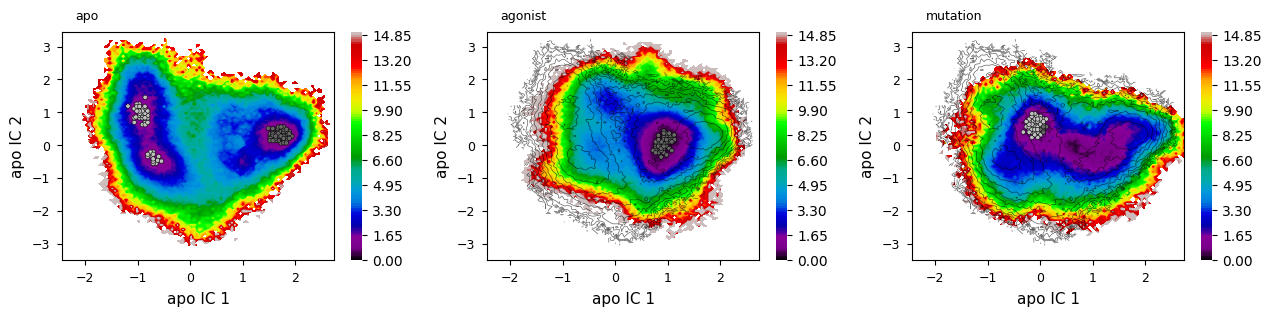

In [15]:
# --- check: landscapes in apo space + extracted frames, re-projected from the written PDBs ---
pairs_wt  = [(2211, 546), (2211, 3571), (2211, 4665), (2211, 6311), (2211, 6519), (2211, 6868), (2211, 7689), (253, 8163), (253, 8288), (253, 8508), (1548, 8163), (1548, 8288), (1548, 8508), (2211, 8163), (2211, 8288), (2211, 8508), (3050, 8163), (3050, 8288), (3050, 8508), (3903, 8163), (3903, 8288), (3903, 8508), (4454, 8163), (4454, 8288), (4454, 8508)]
pairs_mut = [(2211, 546), (2211, 3576), (2211, 4670), (2211, 6316), (2211, 6524), (2211, 6873), (2211, 7694), (253, 8168), (253, 8293), (253, 8513), (1548, 8168), (1548, 8293), (1548, 8513), (2211, 8168), (2211, 8293), (2211, 8513), (3055, 8168), (3055, 8293), (3055, 8513), (3908, 8168), (3908, 8293), (3908, 8513), (4459, 8168), (4459, 8293), (4459, 8513)]
systems = ['apo', 'agonist', 'mutation']
state_colors = {1: '#c1c1c1', 2: '#676767'}   # apo 1 region / apo 2 region

xm0, ym0, e0 = energy2d(x=apo_cat[:, 0], y=apo_cat[:, 1], bins=100, kbt=2.52, weights=apo_w)
e0[np.isinf(e0)] = np.nan
xlim = (apo_cat[:, 0].min(), apo_cat[:, 0].max()); ylim = (apo_cat[:, 1].min(), apo_cat[:, 1].max())

fig, axes = plt.subplots(1, 3, figsize=(4.3*3, 3.3), tight_layout=True)
for ax, system in zip(axes, systems):
    # landscape of this system in apo space (own MSM weights)
    dist = np.load(f"{system}/distances_data_filtered.npy")
    ic = apo_cat if system == 'apo' else apo_model.get_model().transform(np.concatenate(dist))[:, :2]
    sys_tica   = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:, :, :2]
    sys_dtrajs = discretize(sys_tica, k=100)
    weights    = estimate_msm(sys_dtrajs, lag_msm=200).compute_trajectory_weights(np.concatenate(sys_dtrajs))[0]
    xm, ym, e = energy2d(x=ic[:, 0], y=ic[:, 1], bins=100, kbt=2.52, weights=weights)
    e[np.isinf(e)] = np.nan; e[e > 15] = 15
    dt.plots.plot_energy2d(dt.util.EnergyLandscape2d(xm, ym, e, kbt=2.52), ax=ax, levels=100,
                           contourf_kws=dict(cmap='nipy_spectral'), cbar=True, cbar_kws=None, cbar_ax=None)
    if system != 'apo':
        ax.contour(xm0, ym0, e0, levels=12, colors='black', linewidths=0.5, alpha=0.6)

    # re-project the written PDB files (independent check of the extraction)
    pairs = np.array(pairs_mut if system == 'mutation' else pairs_wt)
    ex = pd.read_pickle(f"{system}/extracted-frames-apo-space.pkl")
    rows = []
    for state in sorted(ex['State'].unique()):
        files = sorted(glob.glob(f"{system}/{out_name}/{state}/??_????_{system}.pdb"))
        for f in files:
            X = mda.Universe(f).atoms.positions
            rows.append(np.linalg.norm(X[pairs[:, 0]] - X[pairs[:, 1]], axis=1) / 10.0)
    reproj = apo_model.get_model().transform(np.array(rows))[:, :2]
    dev = np.abs(reproj - ex[['IC1', 'IC2']].values).max()
    print(f"{system}: {len(ex)} frames, max |re-projected - recorded| IC = {dev:.3f}")

    ax.scatter(reproj[:, 0], reproj[:, 1], c=[state_colors[s] for s in ex['apo_state']],
               s=10, edgecolor='black', linewidth=0.4, zorder=5)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    plot_adjust_settings('apo IC 1', 'apo IC 2', ax=ax)
    ax.text(0.05, 1.1, system, transform=ax.transAxes, fontsize=9, va='top')
plt.show()

# Structural Analysis

PYMOL: align macrostates.pdb to experimental_structures/PROCESSED/7f9y-align.pdb 

In [14]:
systems = {'apo' : 2, 
           'agonist': 1, 
           'mutation': 1}

for system, nstates in systems.items():
    for i in range(nstates):
        state = i+1
        print(f'{system}/{state}')
        
        # Input
        files = glob.glob(f'{system}/macrostates_frames/{state}/??_????_*.pdb')
        files.sort()
            
        ref = mda.Universe(f'{system}/macrostates_frames/{state}/7f9y-align.pdb')
        u = mda.Universe(f'{system}/macrostates_frames/{state}/7f9y-align.pdb', files)

        aligner = align.AlignTraj(u, ref, select='chainID A', filename=f'{system}/macrostates_frames/{state}/traj-align.xtc').run()


apo/1


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/base.py:730: UserWarning: Reader has no dt information, set to 1.0 ps
  return self.ts.dt
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/analysis/base.py:562: UserWarning: Reader has no dt information, set to 1.0 ps
  self.times[idx] = ts.time
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/XTC.py:119: UserWarning: Reader has no dt information, set to 1.0 ps
  time = ts.time


apo/2
agonist/1
mutation/1


In [17]:
frame_sets = ['macrostates_frames', 'apo_space_frames']
states     = {'apo': [1, 2], 'agonist': [1], 'mutation': [1]}

dico = {"Frames": [], "System": [], "State": [], "Distance": [], "Tilt-Distance": []}

for frames in frame_sets:
    for system, state_list in states.items():
        for state in state_list:
            topdir = f'{system}/{frames}/{state}'
            print(f'{frames}: {system}/{state}')

            u = mda.Universe(f'{topdir}/7f9y-align.pdb', f'{topdir}/traj-align.xtc')

            res1 = u.select_atoms('name CA and resid 68 and chainID A')    # TM1
            res2 = u.select_atoms('name CA and resid 259 and chainID A')   # TM6
            A    = u.select_atoms('chainID A and resid 239 and name CA')   # L239
            B    = u.select_atoms('chainID B and resid 203 and name CA')   # T203

            for ts in u.trajectory:
                dico['Distance'].append(np.linalg.norm(res1.center_of_mass() - res2.center_of_mass()))
                dico['Tilt-Distance'].append(np.linalg.norm(A.center_of_mass() - B.center_of_mass()))
                dico['Frames'].append(frames)
                dico['System'].append(system)
                dico['State'].append(state)

df = pd.DataFrame(dico)
df.to_pickle('md-gprot-tilt-shift.pkl')
print(df.groupby(['Frames', 'System', 'State'])[['Distance', 'Tilt-Distance']].mean().round(1))

macrostates_frames: apo/1
macrostates_frames: apo/2
macrostates_frames: agonist/1
macrostates_frames: mutation/1
apo_space_frames: apo/1
apo_space_frames: apo/2
apo_space_frames: agonist/1
apo_space_frames: mutation/1
                                   Distance  Tilt-Distance
Frames             System   State                         
apo_space_frames   agonist  1          31.0           29.6
                   apo      1          27.6           26.9
                            2          34.0           29.5
                   mutation 1          28.6           29.7
macrostates_frames agonist  1          32.0           27.8
                   apo      1          27.6           26.9
                            2          34.0           29.5
                   mutation 1          29.0           29.5


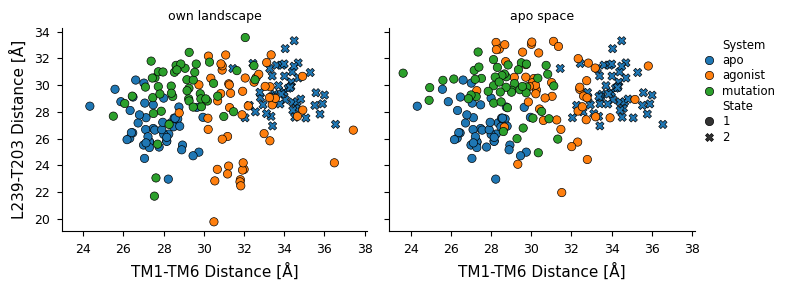

In [18]:
df_md = pd.read_pickle('md-gprot-tilt-shift.pkl')
titles = {'macrostates_frames': 'own landscape', 'apo_space_frames': 'apo space'}

fig, axes = plt.subplots(1, 2, figsize=(8, 3), tight_layout=True, sharex=True, sharey=True)

for ax, (frames, title) in zip(axes, titles.items()):
    sub = df_md[df_md['Frames'] == frames]
    sns.scatterplot(sub, x='Distance', y='Tilt-Distance', hue='System', style='State',
                    hue_order=['apo', 'agonist', 'mutation'], edgecolor='black', ax=ax)
    ax.set_title(title, fontsize=9)
    plot_adjust_settings('TM1-TM6 Distance [Å]', 'L239-T203 Distance [Å]', ax=ax)
    ax.legend([], [], frameon=False)

handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(handles, labels, title='', loc='upper left', fontsize='small', handlelength=0.7,
               labelspacing=0.2, frameon=False, bbox_to_anchor=(1, 1))
sns.despine()
plt.show()

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


    PDB pose  Distance  Tilt-Distance
0  6OS9    C      25.5      27.100000
1  6OSA   NC      24.0      30.700001
2  9P82    C      24.5      32.700001
3  7L0Q    C      24.5      28.500000
4  7L0S   NC      24.4      29.200001


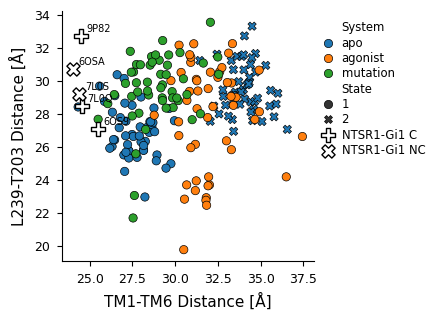

In [14]:
# --- project experimental NTSR1-Gi1 structures into the TM1-TM6 vs L239-T203 space ---
# GHSR/mini-G residues mapped to NTSR1/Gαi1 by sequence alignment, checked structurally
# (receptor superposition: equivalent Cα within 0.6-2.6 Å)
#   GHSR V68 (TM1)  -> NTSR1 L88  (6OS9/6OSA/9P82) / L89  (7L0Q/7L0S numbering)
#   GHSR K259 (TM6) -> NTSR1 R299                   / R304
#   GHSR L239       -> NTSR1 L263                   / L264
#   mini-G T203     -> Gαi1 T329 (chain A in all entries)
exp_dir = 'NTSR1_structures'
exp_structs = {   # pdb: (receptor chain, TM1, TM6, L239-equivalent, G-protein pose)
    '6OS9': ('R', 88, 299, 263, 'C'),
    '6OSA': ('R', 88, 299, 263, 'NC'),
    '9P82': ('R', 88, 299, 263, 'C'),
    '7L0Q': ('C', 89, 304, 264, 'C'),
    '7L0S': ('C', 89, 304, 264, 'NC'),
}

def ca(u, chain, resid):
    g = u.select_atoms(f'chainID {chain} and resid {resid} and name CA and not altloc B')
    assert len(g) >= 1, (chain, resid)
    return g.positions[0]

rows = []
for pdb, (rc, tm1, tm6, l239, pose) in exp_structs.items():
    u = mda.Universe(f'{exp_dir}/{pdb}.pdb')
    rows.append({'PDB': pdb, 'pose': pose,
                 'Distance':      np.linalg.norm(ca(u, rc, tm1) - ca(u, rc, tm6)),
                 'Tilt-Distance': np.linalg.norm(ca(u, rc, l239) - ca(u, 'A', 329))})
df_exp = pd.DataFrame(rows)
print(df_exp.round(1))

# ---- plot: MD macrostate frames + experimental structures ----
fig, ax = plt.subplots(1, 1, figsize=(4.5, 3.3), tight_layout=True)

df_md = pd.read_pickle('md-gprot-tilt-shift.pkl')
sns.scatterplot(df_md, x='Distance', y='Tilt-Distance', hue='System', style='State',
                edgecolor='black', ax=ax)

pose_marker = {'C': 'P', 'NC': 'X'}            # filled plus / filled x
for pose, sub in df_exp.groupby('pose'):
    ax.scatter(sub['Distance'], sub['Tilt-Distance'], marker=pose_marker[pose], s=90,
               color='white', edgecolor='black', linewidth=1, zorder=5,
               label=f'NTSR1-Gi1 {pose}')
for _, r in df_exp.iterrows():
    ax.annotate(r['PDB'], (r['Distance'], r['Tilt-Distance']), xytext=(4, 3),
                textcoords='offset points', fontsize=7)

ax.legend(title='', loc='upper left', fontsize='small', handlelength=0.7, labelspacing=0.2,
          frameon=False, bbox_to_anchor=(1, 1))
plot_adjust_settings('TM1-TM6 Distance [Å]', 'L239-T203 Distance [Å]', ax=ax)
sns.despine()
plt.show()

# Experimentally measured distance

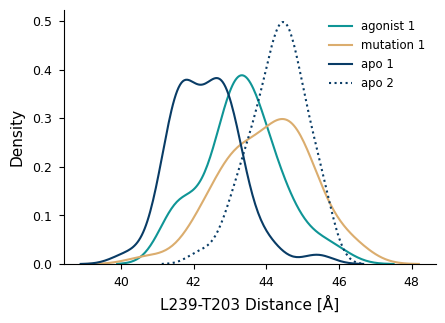

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(4.8, 3.3))

systems = {'agonist': 1, 'mutation': 1, 'apo': 2}

colors = {'mutation':'#dbad6e',
         'agonist':'#0f9596',
         'apo':'#093c66'}

for system, nstates in systems.items():
    for i in range(nstates):
        state = i + 1

        u = mda.Universe(f'{system}/macrostates_frames/{state}/7f9y-align.pdb',
                         f'{system}/macrostates_frames/{state}/traj-align.xtc')

        res1 = u.select_atoms('name CA and resid 239 and chainID A')
        res2 = u.select_atoms('name CA and resid 203 and chainID B')

        distances = []
        for ts in u.trajectory:
            distances.append(np.linalg.norm(res1.positions[0] - res2.positions[0]))

        if state == 1:
            sns.kdeplot(distances, ax=ax, label=f'{system} {state}', color=colors[system])
        else:
            sns.kdeplot(distances, ax=ax, label=f'{system} {state}', color=colors[system], linestyle=':')


plot_adjust_settings('L239-T203 Distance [Å]', 'Density', ax=ax)
ax.legend(title='', fontsize='small', frameon=False, bbox_to_anchor=(1,1))
sns.despine()

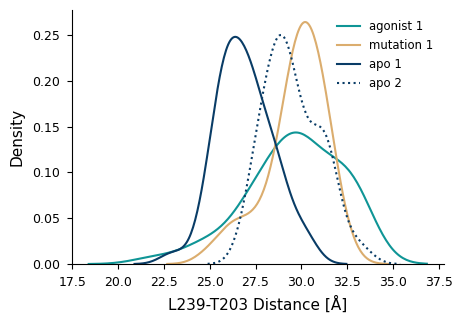

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(4.8, 3.3))

systems = {'agonist': 1, 'mutation': 1, 'apo': 2}

colors = {'mutation':'#dbad6e',
         'agonist':'#0f9596',
         'apo':'#093c66'}

for system, nstates in systems.items():
    for i in range(nstates):
        state = i + 1

        u = mda.Universe(f'{system}/apo_space_frames/{state}/7f9y-align.pdb',
                         f'{system}/apo_space_frames/{state}/traj-align.xtc')

        res1 = u.select_atoms('name CA and resid 239 and chainID A')
        res2 = u.select_atoms('name CA and resid 203 and chainID B')

        distances = []
        for ts in u.trajectory:
            distances.append(np.linalg.norm(res1.positions[0] - res2.positions[0]))

        if state == 1:
            sns.kdeplot(distances, ax=ax, label=f'{system} {state}', color=colors[system])
        else:
            sns.kdeplot(distances, ax=ax, label=f'{system} {state}', color=colors[system], linestyle=':')


plot_adjust_settings('L239-T203 Distance [Å]', 'Density', ax=ax)
ax.legend(title='', fontsize='small', frameon=False, bbox_to_anchor=(1,1))
sns.despine()

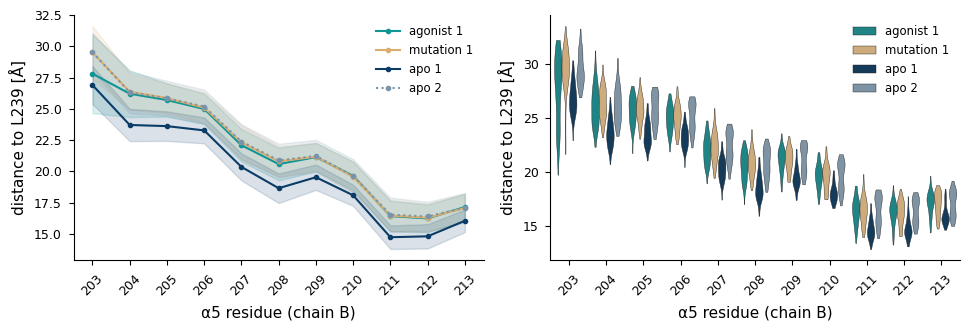

In [8]:
# --- α5 N-cap: separate helix POSITION from local (T203) fraying -----------------
# The single L239–T203 distance mixes two things: how deep α5 sits in the receptor,
# and whether T203 (the very N-cap) is helix-ordered or unfolded. Here we measure
# L239(chain A) to EACH Cα along the α5 N-terminal stretch and look at the profile:
#   • folded, docked helix  -> smooth reproducible curve; the whole curve shifts
#                              up/down with the helix's insertion depth (POSITION)
#   • local unfolding        -> extra spread at that residue + departure from the
#                              neighbour trend, often a bimodal (folded/frayed) split
import matplotlib.colors as mcolors

systems   = {'agonist': 1, 'mutation': 1, 'apo': 2}
colors    = {'mutation': '#dbad6e', 'agonist': '#0f9596', 'apo': '#093c66'}
a5_resids = list(range(203, 214))          # T203 ... 213 (α5 N-terminal half)

def _lighten(c, f=0.45):                    # distinguish the 2nd apo state
    r, g, b = mcolors.to_rgb(c)
    return (r + (1 - r) * f, g + (1 - g) * f, b + (1 - b) * f)

lab_color = {}
for s, n in systems.items():
    for i in range(n):
        lab_color[f'{s} {i+1}'] = colors[s] if i == 0 else _lighten(colors[s])
label_order = list(lab_color)

recs = []
for system, nstates in systems.items():
    for i in range(nstates):
        state = i + 1
        u = mda.Universe(f'{system}/macrostates_frames/{state}/7f9y-align.pdb',
                         f'{system}/macrostates_frames/{state}/traj-align.xtc')
        ref = u.select_atoms('name CA and resid 239 and chainID A')
        a5  = {r: u.select_atoms(f'name CA and resid {r} and chainID B') for r in a5_resids}
        a5  = {r: g for r, g in a5.items() if len(g) == 1}   # keep resolved residues
        for ts in u.trajectory:
            rp = ref.positions[0]
            for r, g in a5.items():
                recs.append({'system': system, 'state': state,
                             'label': f'{system} {state}', 'resid': r,
                             'dist': float(np.linalg.norm(rp - g.positions[0]))})
df_a5 = pd.DataFrame(recs)

fig, axes = plt.subplots(1, 2, figsize=(9.8, 3.4), tight_layout=True)

# Panel A — profile along α5: vertical offset = helix position, band width = local order
ax = axes[0]
for lab in label_order:
    g = df_a5[df_a5.label == lab].groupby('resid')['dist']
    m, sd = g.mean(), g.std()
    st = int(lab.split()[1])
    ax.plot(m.index, m.values, marker='o', ms=3, color=lab_color[lab],
            linestyle=(':' if st == 2 else '-'), label=lab)
    ax.fill_between(m.index, m - sd, m + sd, color=lab_color[lab], alpha=0.15)
ax.set_xticks(a5_resids); ax.tick_params(axis='x', rotation=45)
plot_adjust_settings('α5 residue (chain B)', 'distance to L239 [Å]', ax=ax)
ax.legend(title='', fontsize='small', frameon=False)

# Panel B — per-residue distributions: exposes bimodal folded/frayed populations
ax = axes[1]
sns.violinplot(data=df_a5, x='resid', y='dist', hue='label', hue_order=label_order,
               palette=lab_color, density_norm='width',   # seaborn<0.13: scale='width'
               inner=None, linewidth=0.3, cut=0, ax=ax)
ax.tick_params(axis='x', rotation=45)
plot_adjust_settings('α5 residue (chain B)', 'distance to L239 [Å]', ax=ax)
ax.legend(title='', fontsize='small', frameon=False, bbox_to_anchor=(1, 1))

sns.despine()
plt.show()


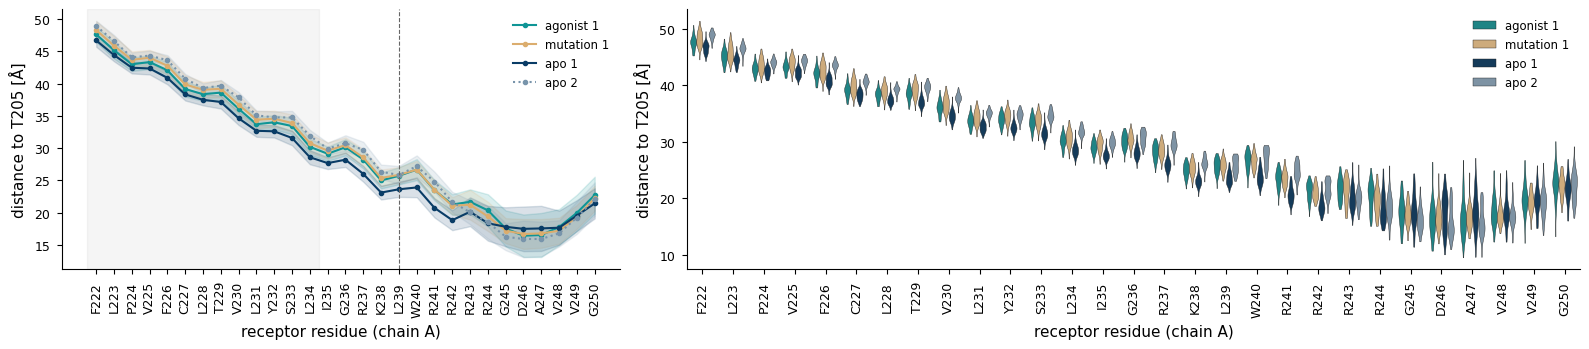

In [18]:
# --- fixed α5 T203, sweep receptor residues along cytoplasmic TM5 -> ICL3 ---------
# Distance from T203 (chain B) to EACH receptor Cα (chain A) in the window:
#   • α5 / mini-G displaced    -> whole profile shifted up/down along TM5
#   • local receptor change     -> departure confined to a few receptor residues
#                                  (extra spread / bimodality at TM5 end or ICL3)
import matplotlib.colors as mcolors

systems    = {'agonist': 1, 'mutation': 1, 'apo': 2}
colors     = {'mutation': '#dbad6e', 'agonist': '#0f9596', 'apo': '#093c66'}
A5_RESID   = 205                           # fixed mini-G residue (chain B)
rec_resids = list(range(222, 251))         # TM5 cytoplasmic half (to 234) -> ICL3

def _lighten(c, f=0.45):                    # distinguish the 2nd apo state
    r, g, b = mcolors.to_rgb(c)
    return (r + (1 - r) * f, g + (1 - g) * f, b + (1 - b) * f)

lab_color = {}
for s, n in systems.items():
    for i in range(n):
        lab_color[f'{s} {i+1}'] = colors[s] if i == 0 else _lighten(colors[s])
label_order = list(lab_color)

recs = []
for system, nstates in systems.items():
    for i in range(nstates):
        state = i + 1
        u = mda.Universe(f'{system}/macrostates_frames/{state}/7f9y-align.pdb',
                         f'{system}/macrostates_frames/{state}/traj-align.xtc')
        fixed = u.select_atoms(f'name CA and resid {A5_RESID} and chainID B')
        rec   = {r: u.select_atoms(f'name CA and resid {r} and chainID A') for r in rec_resids}
        rec   = {r: g for r, g in rec.items() if len(g) == 1}   # keep resolved residues
        for ts in u.trajectory:
            fp = fixed.positions[0]
            for r, g in rec.items():
                recs.append({'system': system, 'state': state,
                             'label': f'{system} {state}', 'resid': r,
                             'dist': float(np.linalg.norm(fp - g.positions[0]))})
df_rec = pd.DataFrame(recs)

# tick labels with residue names (sequence identical in all systems)
ticklabels = [f'{mda.lib.util.convert_aa_code(rec[r].resnames[0])}{r}' for r in rec_resids]

fig, axes = plt.subplots(1, 2, figsize=(16, 3.6), tight_layout=True,
                         gridspec_kw={'width_ratios': [1, 1.6]})

# Panel A — profile along TM5/ICL3: offset = T203 position, band width = local order
ax = axes[0]
for lab in label_order:
    g = df_rec[df_rec.label == lab].groupby('resid')['dist']
    m, sd = g.mean(), g.std()
    st = int(lab.split()[1])
    ax.plot(m.index, m.values, marker='o', ms=3, color=lab_color[lab],
            linestyle=(':' if st == 2 else '-'), label=lab)
    ax.fill_between(m.index, m - sd, m + sd, color=lab_color[lab], alpha=0.15)
ax.axvspan(rec_resids[0] - 0.5, 234.5, color='grey', alpha=0.08, zorder=0)   # TM5
ax.axvline(239, color='0.4', lw=0.8, ls='--')                                # L239
ax.set_xticks(rec_resids); ax.set_xticklabels(ticklabels, rotation=90, fontsize=7)
plot_adjust_settings('receptor residue (chain A)', f'distance to T{A5_RESID} [Å]', ax=ax)
ax.legend(title='', fontsize='small', frameon=False)

# Panel B — per-residue distributions: exposes bimodal / state-specific populations
ax = axes[1]
sns.violinplot(data=df_rec, x='resid', y='dist', hue='label', hue_order=label_order,
               palette=lab_color, density_norm='width',   # seaborn<0.13: scale='width'
               inner=None, linewidth=0.3, cut=0, ax=ax)
ax.set_xticks(range(len(rec_resids))); ax.set_xticklabels(ticklabels, rotation=90, fontsize=7)
plot_adjust_settings('receptor residue (chain A)', f'distance to T{A5_RESID} [Å]', ax=ax)
ax.legend(title='', fontsize='small', frameon=False, bbox_to_anchor=(1, 1))

sns.despine()
plt.show()

Kruskal-Wallis: H=102.015, p=5.732e-22, n per group=[50, 50, 50, 50]

Pairwise (Mann-Whitney U, Bonferroni-corrected):
  agonist vs mutation  p_bonf=1.000e+00  |delta|=0.11 (negligible)
  apo 1 vs agonist     p_bonf=1.467e-10  |delta|=0.78 (large)
  apo 1 vs apo 2       p_bonf=1.440e-15  |delta|=0.95 (large)
  apo 1 vs mutation    p_bonf=1.954e-12  |delta|=0.85 (large)
  apo 2 vs agonist     p_bonf=4.227e-06  |delta|=0.58 (large)
  apo 2 vs mutation    p_bonf=1.169e-04  |delta|=0.50 (large)


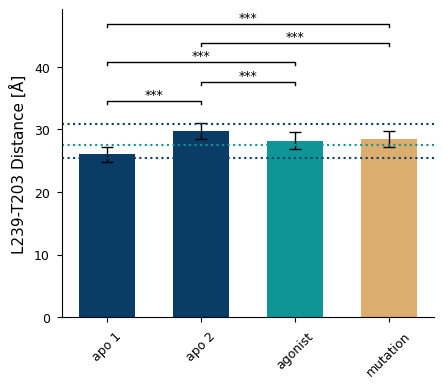

In [20]:
from itertools import combinations
from scipy.stats import kruskal, mannwhitneyu

fig, ax = plt.subplots(1, 1, figsize=(4.8, 4))

systems = {'apo': 2, 'agonist': 1, 'mutation': 1}
colors = {'mutation': '#dbad6e', 'agonist': '#0f9596', 'apo': '#093c66'}

# ---- collect raw per-frame distances per group ----
data = {}   # label -> np.array of distances
dico = {'label': [], 'mean': [], 'std': []}

for system, nstates in systems.items():
    for i in range(nstates):
        state = i + 1
        u = mda.Universe(f'{system}/macrostates_frames/{state}/7f9y-align.pdb',
                         f'{system}/macrostates_frames/{state}/traj-align.xtc')
        res1 = u.select_atoms('name CA and resid 237 and chainID A')
        res2 = u.select_atoms('name CA and resid 205 and chainID B')

        distances = [np.linalg.norm(res1.center_of_mass() - res2.center_of_mass())
                     for ts in u.trajectory]
        distances = np.asarray(distances)

        label = f'{system} {state}' if nstates > 1 else system
        data[label] = distances
        dico['label'].append(label)
        dico['mean'].append(distances.mean())
        dico['std'].append(distances.std())

df = pd.DataFrame(dico)
labels = list(df['label'])

# ---- 1) omnibus Kruskal-Wallis ----
H, p_omnibus = kruskal(*[data[l] for l in labels])
print(f"Kruskal-Wallis: H={H:.3f}, p={p_omnibus:.3e}, n per group={[len(data[l]) for l in labels]}")

# ---- 2) pairwise Mann-Whitney U + Bonferroni + Cliff's delta ----
def cliffs_delta(a, b):
    a = np.asarray(a); b = np.asarray(b)
    gt = sum((a[:, None] > b[None, :]).sum(axis=1))
    lt = sum((a[:, None] < b[None, :]).sum(axis=1))
    return (gt - lt) / (len(a) * len(b))

pairs = list(combinations(range(len(labels)), 2))
results = []
if p_omnibus < 0.05:                      # only probe pairs if omnibus is significant
    m = len(pairs)                        # number of comparisons
    for i, j in pairs:
        li, lj = labels[i], labels[j]
        U, p = mannwhitneyu(data[li], data[lj], alternative='two-sided')
        d = cliffs_delta(data[li], data[lj])
        p_bonf = min(p * m, 1.0)          # Bonferroni: multiply by m, cap at 1
        results.append({'i': i, 'j': j, 'pair': f'{li} vs {lj}',
                        'p_raw': p, 'p_bonf': p_bonf, 'delta': d})

    print("\nPairwise (Mann-Whitney U, Bonferroni-corrected):")
    for r in sorted(results, key=lambda r: r['pair']):
        mag = ('negligible' if abs(r['delta']) < 0.147 else
               'small'      if abs(r['delta']) < 0.33  else
               'medium'     if abs(r['delta']) < 0.474 else 'large')
        print(f"  {r['pair']:<20} p_bonf={r['p_bonf']:.3e}  |delta|={abs(r['delta']):.2f} ({mag})")
else:
    print("\nOmnibus not significant -> no pairwise tests, no annotations.")

# ---- bar plot ----
bar_colors = [colors[l.split()[0]] for l in labels]
ax.bar(df['label'], df['mean'], yerr=df['std'], color=bar_colors,
       capsize=4, error_kw=dict(elinewidth=1), width=0.6)
plot_adjust_settings('', 'L239-T203 Distance [Å]', ax=ax)
ax.tick_params(axis='x', rotation=45)

# experimental measurements
ax.axhline(y=25.49, linestyle=':', color=colors['apo'])
ax.axhline(y=30.82, linestyle=':', color=colors['apo'])
ax.axhline(y=27.45, linestyle=':', color=colors['agonist'])

# ---- annotate only significant pairs ----
def stars(p):
    return '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else None

sig = [r for r in results if stars(r['p_bonf'])]
sig.sort(key=lambda r: abs(r['i'] - r['j']))   # short brackets first -> stack neatly

y0 = (df['mean'] + df['std']).max()
h = 0.015 * y0            # bracket height
pad = 0.1 * y0          # vertical gap between stacked brackets
level = 0
for r in sig:
    x1, x2 = r['i'], r['j']
    y = y0 + pad * (level + 1)
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.0, c='black')
    ax.text((x1 + x2) / 2, y + h, stars(r['p_bonf']),
            ha='center', va='bottom', fontsize=9)
    level += 1

sns.despine()

In [5]:
# --- per-frame L239(A)-T203(B) Cα distance for every frame in the filtered TICA arrays ---
from joblib import Parallel, delayed

src_root = "/Volumes/LaCie/260110_msm_GHSR+miniG_smart_features"
classes = {"apo":      ['M0', 'U0', 'U1', 'V2'],
           "agonist":  ['M0', 'U0', 'U1', 'V2', 'V3', 'V4'],
           "mutation": ['M0', 'U0', 'U1']}
# 0-based atom indices in protein.gro (checked: LEU239 CA / THR203 CA, +5 shift from A204E)
ca_idx = {"apo": (3288, 8134), "agonist": (3288, 8134), "mutation": (3293, 8139)}

def traj_dist(path, i1, i2):
    u = mda.Universe(f"{path}/protein.gro", f"{path}/protein-pbc.xtc")
    ag = u.atoms[[i1, i2]]
    # featurization frame k = trajectory frame 5k, k < 1000
    return np.array([np.linalg.norm(ag.positions[0] - ag.positions[1])
                     for ts in u.trajectory[0:5000:5]])

for system, topdirs in classes.items():
    out = f"{system}/L239_T203_dist_filtered.npy"
    if os.path.exists(out):
        print(system, "cached")
        continue

    # same trajectory order as the featurization, then the same masks as for TICA
    paths = []
    for tmp in topdirs:
        subdirs_int = sorted(int(x) for x in next(os.walk(f"{src_root}/{system}/{tmp}"))[1] if len(x) <= 2)
        paths += [f"{src_root}/{system}/{tmp}/{j}/{k}" for j in subdirs_int for k in range(4)]
    paths = np.array(paths)
    for mask in sorted(glob.glob(f"{system}/mask_v?.npy")):
        paths = paths[~np.load(mask)]

    n_traj = np.load(f"{system}/TICA_distances_20_ns_filtered.npy", mmap_mode='r').shape[0]
    assert len(paths) == n_traj, f"{system}: {len(paths)} paths vs {n_traj} TICA trajectories"

    i1, i2 = ca_idx[system]
    dist = Parallel(n_jobs=8)(delayed(traj_dist)(p, i1, i2) for p in tqdm(paths, desc=system))
    dist = np.stack(dist)                        # (n_traj, 1000), Å
    np.save(out, dist)
    print(system, dist.shape)

apo:   0%|          | 0/432 [00:00<?, ?it/s]

apo (432, 1000)


agonist:   0%|          | 0/780 [00:00<?, ?it/s]

agonist (780, 1000)


mutation:   0%|          | 0/290 [00:00<?, ?it/s]

mutation (290, 1000)


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/deeptime/clustering/_kmeans.py:466: UserWarning: Algorithm did not reach convergence criterion of 1e-05 in 50 iterations. Consider increasing max_iter.
  warnings.warn(f"Algorithm did not reach convergence criterion"


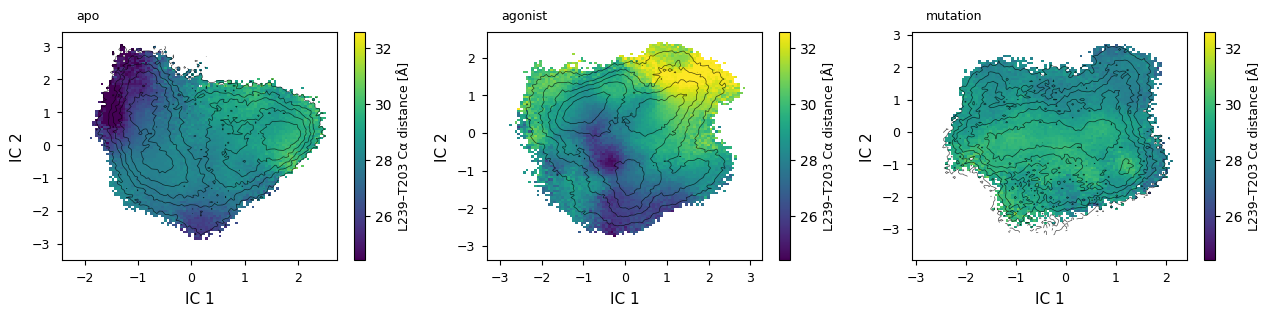

In [6]:
# --- IC1/IC2 landscapes colored by MSM-weighted mean L239-T203 distance per bin ---
tica_lag  = 20
systems   = ['apo', 'agonist', 'mutation']

MIN_COUNT = 5        # hide bins with fewer frames (noisy edges)
bins      = 100

res = {}
for system in systems:
    tica_arr = np.load(f"{system}/TICA_distances_{tica_lag}_ns_filtered.npy")[:, :, :2]
    tica_concatenated = np.concatenate(tica_arr)
    dtrajs = discretize(tica_arr, k=100)
    msm = estimate_msm(dtrajs, lag_msm=200)
    weights = msm.compute_trajectory_weights(np.concatenate(dtrajs))[0]
    d = np.concatenate(np.load(f"{system}/L239_T203_dist_filtered.npy"))
    assert len(d) == len(tica_concatenated)

    x, y = tica_concatenated[:, 0], tica_concatenated[:, 1]
    wsum, xe, ye = np.histogram2d(x, y, bins=bins, weights=weights)
    dsum, _, _   = np.histogram2d(x, y, bins=[xe, ye], weights=weights * d)
    cnt, _, _    = np.histogram2d(x, y, bins=[xe, ye])
    with np.errstate(invalid='ignore', divide='ignore'):
        dmean = (dsum / wsum).T
    dmean[(cnt.T < MIN_COUNT) | ~np.isfinite(dmean)] = np.nan

    xm, ym, energy = energy2d(x=x, y=y, bins=bins, kbt=2.52, weights=weights)
    energy[np.isinf(energy)] = np.nan
    res[system] = (xe, ye, dmean, xm, ym, energy)

# shared color scale across systems so panels are comparable
allv = np.concatenate([r[2][np.isfinite(r[2])] for r in res.values()])
vmin, vmax = np.percentile(allv, [1, 99])

fig, axes = plt.subplots(1, 3, figsize=(4.3*3, 3.3), tight_layout=True)
for ax, system in zip(axes, systems):
    xe, ye, dmean, xm, ym, energy = res[system]
    im = ax.pcolormesh(xe, ye, dmean, cmap='viridis', vmin=vmin, vmax=vmax, shading='flat')
    ax.contour(xm, ym, energy, levels=[1.65, 3.3, 4.95, 6.6, 9.9],
               colors='black', linewidths=0.5, alpha=0.7)    # free-energy isolines [kJ/mol]
    plot_adjust_settings('IC 1', 'IC 2', ax=ax)
    ax.text(0.05, 1.1, system, transform=ax.transAxes, fontsize=9, va='top')
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label('L239–T203 Cα distance [Å]', fontsize=9)
plt.show()

Kruskal-Wallis: H=154.705, p=2.545e-33, n per group=[50, 50, 50, 50]

Pairwise (Mann-Whitney U, Bonferroni-corrected):
  agonist vs mutation  p_bonf=3.251e-12  |delta|=0.84 (large)
  apo 1 vs agonist     p_bonf=6.850e-17  |delta|=0.99 (large)
  apo 1 vs apo 2       p_bonf=4.240e-17  |delta|=1.00 (large)
  apo 1 vs mutation    p_bonf=9.405e-05  |delta|=0.50 (large)
  apo 2 vs agonist     p_bonf=2.475e-09  |delta|=0.73 (large)
  apo 2 vs mutation    p_bonf=8.698e-17  |delta|=0.99 (large)


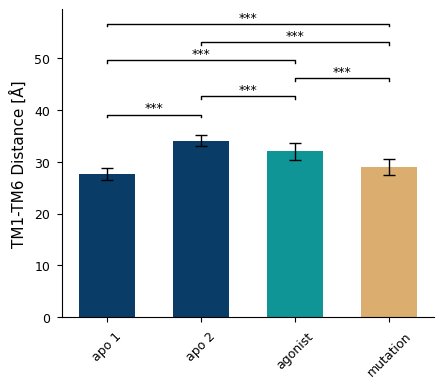

In [24]:
# --- TM1-TM6 intracellular distance per state (same stats/plot as L239-T203) ------
from itertools import combinations
from scipy.stats import kruskal, mannwhitneyu

fig, ax = plt.subplots(1, 1, figsize=(4.8, 4))

systems = {'apo': 2, 'agonist': 1, 'mutation': 1}
colors = {'mutation': '#dbad6e', 'agonist': '#0f9596', 'apo': '#093c66'}

# ---- collect raw per-frame TM1-TM6 Cα distances per group ----
data = {}   # label -> np.array of distances
dico = {'label': [], 'mean': [], 'std': []}

for system, nstates in systems.items():
    for i in range(nstates):
        state = i + 1
        u = mda.Universe(f'{system}/macrostates_frames/{state}/7f9y-align.pdb',
                         f'{system}/macrostates_frames/{state}/traj-align.xtc')
        res1 = u.select_atoms('name CA and resid 68 and chainID A')    # TM1
        res2 = u.select_atoms('name CA and resid 259 and chainID A')   # TM6

        distances = [np.linalg.norm(res1.center_of_mass() - res2.center_of_mass())
                     for ts in u.trajectory]
        distances = np.asarray(distances)

        label = f'{system} {state}' if nstates > 1 else system
        data[label] = distances
        dico['label'].append(label)
        dico['mean'].append(distances.mean())
        dico['std'].append(distances.std())

df = pd.DataFrame(dico)
labels = list(df['label'])

# ---- 1) omnibus Kruskal-Wallis ----
H, p_omnibus = kruskal(*[data[l] for l in labels])
print(f"Kruskal-Wallis: H={H:.3f}, p={p_omnibus:.3e}, n per group={[len(data[l]) for l in labels]}")

# ---- 2) pairwise Mann-Whitney U + Bonferroni + Cliff's delta ----
def cliffs_delta(a, b):
    a = np.asarray(a); b = np.asarray(b)
    gt = sum((a[:, None] > b[None, :]).sum(axis=1))
    lt = sum((a[:, None] < b[None, :]).sum(axis=1))
    return (gt - lt) / (len(a) * len(b))

pairs = list(combinations(range(len(labels)), 2))
results = []
if p_omnibus < 0.05:
    m = len(pairs)
    for i, j in pairs:
        li, lj = labels[i], labels[j]
        U, p = mannwhitneyu(data[li], data[lj], alternative='two-sided')
        d = cliffs_delta(data[li], data[lj])
        p_bonf = min(p * m, 1.0)
        results.append({'i': i, 'j': j, 'pair': f'{li} vs {lj}',
                        'p_raw': p, 'p_bonf': p_bonf, 'delta': d})
    print("\nPairwise (Mann-Whitney U, Bonferroni-corrected):")
    for r in sorted(results, key=lambda r: r['pair']):
        mag = ('negligible' if abs(r['delta']) < 0.147 else
               'small'      if abs(r['delta']) < 0.33  else
               'medium'     if abs(r['delta']) < 0.474 else 'large')
        print(f"  {r['pair']:<20} p_bonf={r['p_bonf']:.3e}  |delta|={abs(r['delta']):.2f} ({mag})")
else:
    print("\nOmnibus not significant -> no pairwise tests, no annotations.")

# ---- bar plot ----
bar_colors = [colors[l.split()[0]] for l in labels]
ax.bar(df['label'], df['mean'], yerr=df['std'], color=bar_colors,
       capsize=4, error_kw=dict(elinewidth=1), width=0.6)
plot_adjust_settings('', 'TM1-TM6 Distance [Å]', ax=ax)
ax.tick_params(axis='x', rotation=45)

# ---- annotate only significant pairs ----
def stars(p):
    return '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else None

sig = [r for r in results if stars(r['p_bonf'])]
sig.sort(key=lambda r: abs(r['i'] - r['j']))

y0 = (df['mean'] + df['std']).max()
h = 0.015 * y0
pad = 0.1 * y0
level = 0
for r in sig:
    x1, x2 = r['i'], r['j']
    y = y0 + pad * (level + 1)
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.0, c='black')
    ax.text((x1 + x2) / 2, y + h, stars(r['p_bonf']),
            ha='center', va='bottom', fontsize=9)
    level += 1

sns.despine()


# GHSR : miniG interface

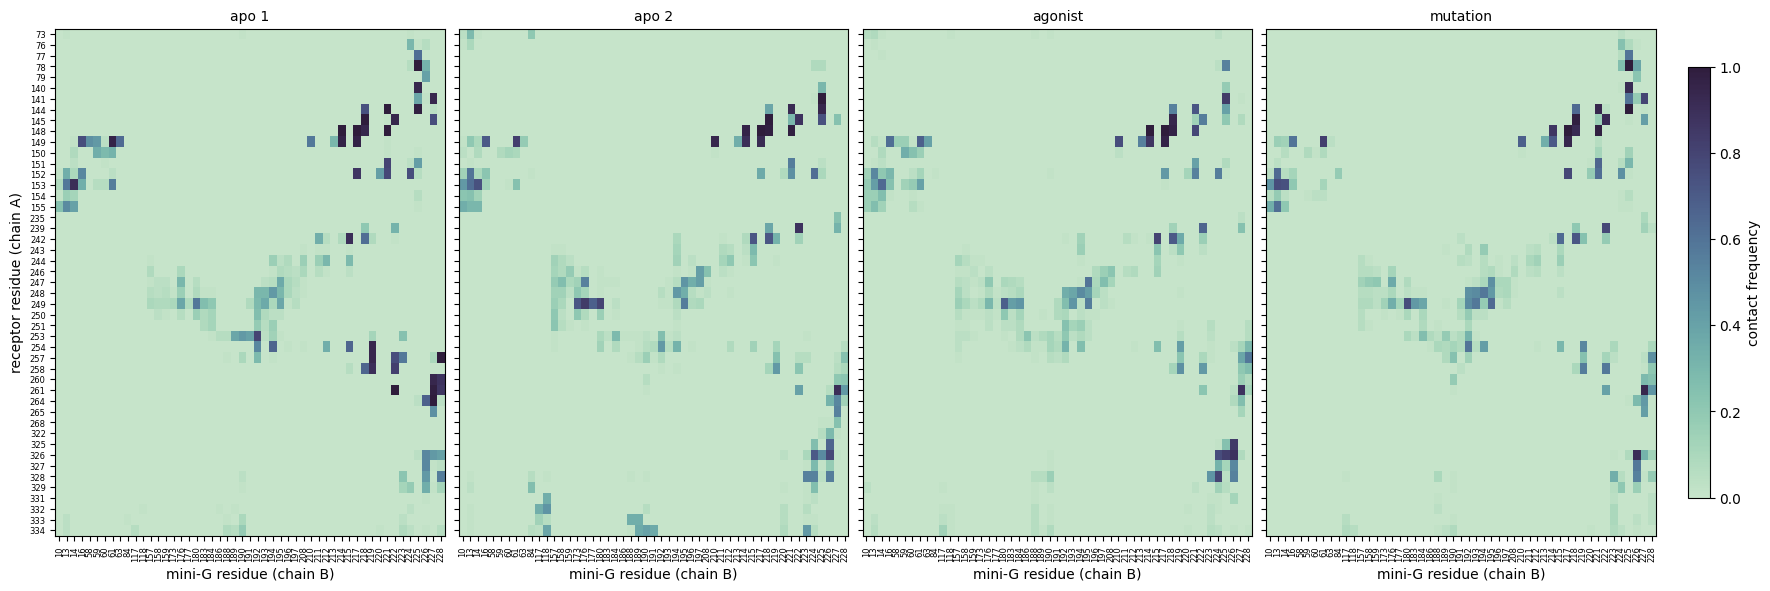

In [10]:
# --- receptor:mini-G interface contact-frequency maps (all 4 states) --------------
# contact = any chain A (receptor) heavy atom within CUTOFF of a chain B (mini-G)
# heavy atom in a given frame; frequency = fraction of frames the residue pair
# is in contact. Rows = receptor residues, cols = mini-G residues, shared across
# panels so the maps are directly comparable.
from MDAnalysis.lib.distances import capped_distance

CUTOFF   = 4.5     # Å, heavy-atom contact distance
DISP_MIN = 0.20    # only show residue pairs reaching this freq in >=1 state

panel_states = [('apo', 1, 'apo 1'), ('apo', 2, 'apo 2'),
                ('agonist', 1, 'agonist'), ('mutation', 1, 'mutation')]

freqs = {}                      # label -> (uA, uB, freq_matrix)
for system, state, label in panel_states:
    base = f'{system}/macrostates_frames/{state}'
    u = mda.Universe(f'{base}/7f9y-align.pdb', f'{base}/traj-align.xtc')
    A = u.select_atoms('chainID A and not name H*')      # receptor heavy atoms
    B = u.select_atoms('chainID B and resid 1:250 and not name H*')  # mini-G heavy atoms
    # note: mutation PDB mislabels 5 atoms of receptor VAL334 (C/OT1/OT2/HG22/HG23)
    # as chain B resid 334; resid 1:250 drops that artifact (real mini-G is 1-228)

    uA = np.unique(A.resids); uB = np.unique(B.resids)
    iA = np.searchsorted(uA, A.resids)                   # atom -> row index
    iB = np.searchsorted(uB, B.resids)                   # atom -> col index
    nB = len(uB)

    count = np.zeros((len(uA), nB))
    nfr = 0
    for ts in u.trajectory:
        pr = capped_distance(A.positions, B.positions, max_cutoff=CUTOFF,
                             box=None, return_distances=False)
        nfr += 1
        if len(pr) == 0:
            continue
        lin = iA[pr[:, 0]] * nB + iB[pr[:, 1]]           # residue-pair id
        r, c = np.divmod(np.unique(lin), nB)             # unique pairs this frame
        count[r, c] += 1
    freqs[label] = (uA, uB, count / nfr)

# shared residue axes = union across states (constructs are identical, but be safe)
rowsA = np.unique(np.concatenate([f[0] for f in freqs.values()]))
colsB = np.unique(np.concatenate([f[1] for f in freqs.values()]))
mats = {}
for lab, (uA, uB, fm) in freqs.items():
    M = np.zeros((len(rowsA), len(colsB)))
    M[np.searchsorted(rowsA, uA)[:, None], np.searchsorted(colsB, uB)[None, :]] = fm
    mats[lab] = M

# keep only interface residues (reach DISP_MIN in at least one state)
stack = np.stack(list(mats.values()))
row_keep = np.where(stack.max(axis=(0, 2)) >= DISP_MIN)[0]
col_keep = np.where(stack.max(axis=(0, 1)) >= DISP_MIN)[0]
rowsA_k, colsB_k = rowsA[row_keep], colsB[col_keep]

vmax = stack.max()
cmap = sns.cubehelix_palette(start=.5, rot=-.6, as_cmap=True)

fig, axes = plt.subplots(1, 4, figsize=(4.4*4, 5.8), sharey=True,
                         constrained_layout=True)
for ax, (_, _, label) in zip(axes, panel_states):
    M = mats[label][np.ix_(row_keep, col_keep)]
    im = ax.imshow(M, aspect='auto', cmap=cmap, vmin=0, vmax=vmax, origin='upper')
    ax.set_xticks(range(len(colsB_k))); ax.set_xticklabels(colsB_k, rotation=90, fontsize=6)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('mini-G residue (chain B)', fontsize=10)
axes[0].set_yticks(range(len(rowsA_k))); axes[0].set_yticklabels(rowsA_k, fontsize=6)
axes[0].set_ylabel('receptor residue (chain A)', fontsize=10)

cbar = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, shrink=0.85)
cbar.set_label('contact frequency', fontsize=10)
plt.show()


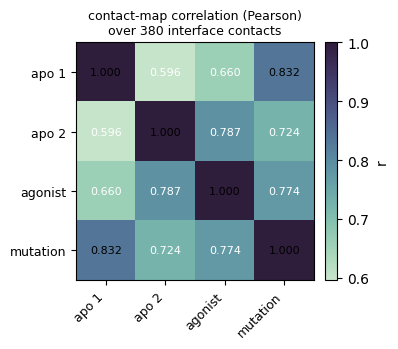

Pearson r over union of interface contacts:
          apo 1  apo 2  agonist  mutation
apo 1     1.000  0.596    0.660     0.832
apo 2     0.596  1.000    0.787     0.724
agonist   0.660  0.787    1.000     0.774
mutation  0.832  0.724    0.774     1.000


In [11]:
# --- state-vs-state correlation of the interface contact maps (4x4) --------------
# Reuses `mats` / `panel_states` from the heatmap cell. Correlation is taken over
# the UNION of real contact pairs (contact in >=1 state) so the shared background
# of never-touching residue pairs doesn't inflate every value toward 1.
labels = [lab for *_, lab in panel_states]
stack  = np.stack([mats[l] for l in labels])          # (4, nA, nB)
mask   = stack.max(axis=0) > 0.05                      # pairs that are real contacts
V      = np.stack([mats[l][mask] for l in labels])     # (4, n_contacts)

Cp = np.corrcoef(V)                                    # Pearson across states
n_pairs = int(mask.sum())

fig, ax = plt.subplots(1, 1, figsize=(4.2, 3.6), tight_layout=True)
im = ax.imshow(Cp, cmap=sns.cubehelix_palette(start=.5, rot=-.6, as_cmap=True),
               vmin=Cp[~np.eye(4, dtype=bool)].min(), vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{Cp[i, j]:.3f}', ha='center', va='center', fontsize=8,
                color='white' if Cp[i, j] < 0.5 * (1 + Cp[~np.eye(4,dtype=bool)].min()) else 'black')
ax.set_xticks(range(4)); ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(4)); ax.set_yticklabels(labels, fontsize=9)
ax.set_title(f'contact-map correlation (Pearson)\nover {n_pairs} interface contacts', fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='r')
plt.show()

print("Pearson r over union of interface contacts:")
print(pd.DataFrame(Cp, index=labels, columns=labels).round(3))


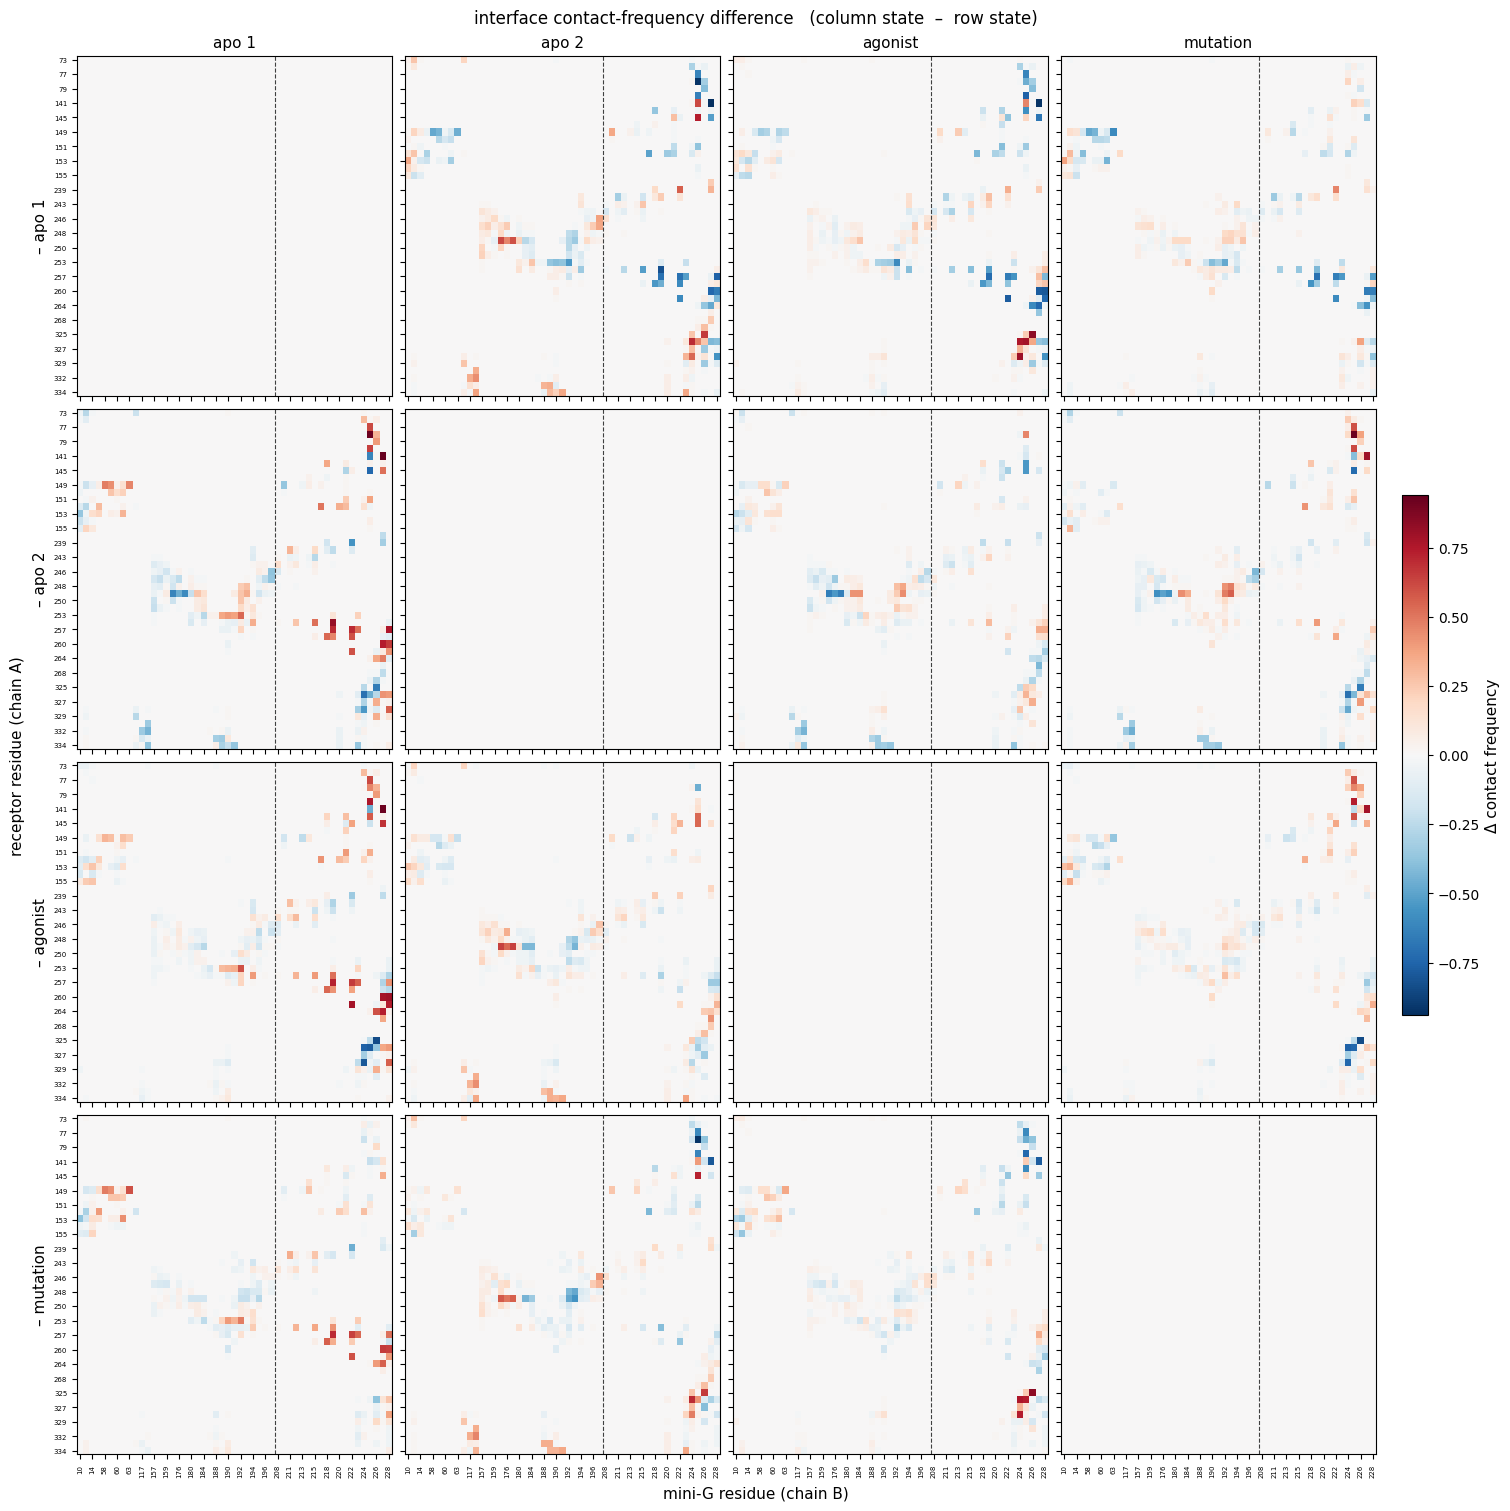

In [12]:
# --- all-vs-all difference maps: contact_freq(col state) - contact_freq(row state) -
# Reuses `mats`, `row_keep`/`col_keep`, `rowsA_k`/`colsB_k`, `panel_states` from the
# heatmap cell. Red = contact stronger in the COLUMN state, blue = stronger in the ROW
# state. Upper/lower triangles are mirror images (A-B = -(B-A)); diagonal is zero.
labels = [lab for *_, lab in panel_states]

diffs = {(li, lj): (mats[lj] - mats[li])[np.ix_(row_keep, col_keep)]
         for li in labels for lj in labels}
vmax = max(np.abs(D).max() for D in diffs.values())

fig, axes = plt.subplots(4, 4, figsize=(15, 15), sharex=True, sharey=True,
                         constrained_layout=True)
for i, li in enumerate(labels):
    for j, lj in enumerate(labels):
        ax = axes[i, j]
        im = ax.imshow(diffs[(li, lj)], aspect='auto', cmap='RdBu_r',
                       vmin=-vmax, vmax=vmax, origin='upper')
        ax.axvline(np.searchsorted(colsB_k, 203) - 0.5, color='0.25',
                   lw=0.8, ls='--')   # α5 helix start (mini-G resid 203)
        if i == j:                                   # zero diagonal -> grey out
            ax.imshow(np.zeros_like(diffs[(li, lj)]), aspect='auto',
                      cmap='Greys', vmin=0, vmax=1, alpha=0.06, origin='upper')
        if i == 0:
            ax.set_title(lj, fontsize=11)
        if j == 0:
            ax.set_ylabel(f'– {li}', fontsize=11)
            ax.set_yticks(range(0, len(rowsA_k), 2))
            ax.set_yticklabels(rowsA_k[::2], fontsize=5)
        if i == 3:
            ax.set_xticks(range(0, len(colsB_k), 2))
            ax.set_xticklabels(colsB_k[::2], rotation=90, fontsize=5)

fig.suptitle('interface contact-frequency difference   (column state  –  row state)',
             fontsize=12)
fig.supxlabel('mini-G residue (chain B)', fontsize=11)
fig.supylabel('receptor residue (chain A)', fontsize=11)
cbar = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, shrink=0.6)
cbar.set_label('Δ contact frequency', fontsize=11)
plt.show()

# ECL2 / ICL2 flexibility

Mean Cα RMSF [Å] per loop (± residue-to-residue SD):
  apo 1      ICL2: 1.69±0.53   ECL2: 1.57±0.46
  apo 2      ICL2: 2.47±0.58   ECL2: 1.72±0.44
  agonist    ICL2: 2.81±1.16   ECL2: 1.22±0.21
  mutation   ICL2: 2.19±0.54   ECL2: 3.60±0.87


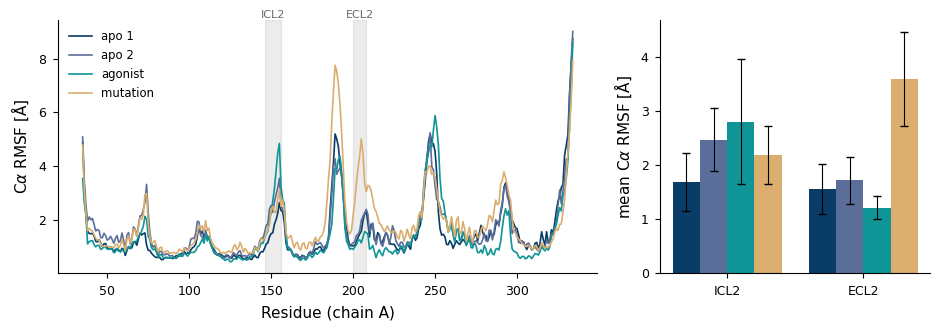

In [86]:
from MDAnalysis.analysis import align, rms

# ---- TM-core alignment selection (chain A CA, helix interiors only) ----
core_sel = ("chainID A and name CA and "
            "(resid 42:66 77:101 118:144 158:180 210:234 255:285 296:319)")

# states to assess
states = [('apo', 1, 'apo 1'),
          ('apo', 2, 'apo 2'),
          ('agonist', 1, 'agonist'),
          ('mutation', 1, 'mutation')]

palette = {'apo 1': '#093c66', 'apo 2': '#5a6e99',
           'agonist': '#0f9596', 'mutation': '#dbad6e'}

loops = {'ICL2': (146, 156), 'ECL2': (200, 208)}

# ---- compute per-residue Cα RMSF for each state ----
rmsf_data = {}   # label -> (resids, rmsf)
for system, state, label in states:
    base = f'{system}/macrostates_frames/{state}'
    ref = mda.Universe(f'{base}/7f9y-align.pdb')
    u = mda.Universe(f'{base}/7f9y-align.pdb', f'{base}/traj-align.xtc')

    # align ensemble to reference on the TM core (in memory -> no file written)
    align.AlignTraj(u, ref, select=core_sel, in_memory=True).run()

    # per-residue RMSF on chain A CA
    ca = u.select_atoms('chainID A and name CA')
    R = rms.RMSF(ca).run()
    rmsf_data[label] = (ca.resids.copy(), R.results.rmsf.copy())

# ---- summary: mean RMSF per loop per state ----
print("Mean Cα RMSF [Å] per loop (± residue-to-residue SD):")
summary = {loop: {} for loop in loops}
for label, (resids, rmsf) in rmsf_data.items():
    row = []
    for loop, (lo, hi) in loops.items():
        m = (resids >= lo) & (resids <= hi)
        summary[loop][label] = (rmsf[m].mean(), rmsf[m].std())
        row.append(f"{loop}: {rmsf[m].mean():.2f}±{rmsf[m].std():.2f}")
    print(f"  {label:<10} " + "   ".join(row))

# ---- plot ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.4),
                               gridspec_kw={'width_ratios': [2, 1]}, tight_layout=True)

# (a) per-residue RMSF, one line per state, loop windows shaded
for label, (resids, rmsf) in rmsf_data.items():
    ax1.plot(resids, rmsf, label=label, color=palette[label], lw=1.2)

for loop, (lo, hi) in loops.items():
    ax1.axvspan(lo, hi, color='grey', alpha=0.15, zorder=0)
    ax1.text((lo + hi) / 2, ax1.get_ylim()[1], loop, ha='center', va='bottom',
             fontsize=8, color='dimgrey')

ax1.legend(frameon=False, fontsize='small')
plot_adjust_settings('Residue (chain A)', r'C$\alpha$ RMSF [Å]', ax=ax1)

# (b) per-loop mean RMSF, grouped bars
loop_names = list(loops)
labels = [lab for _, _, lab in states]
x = np.arange(len(loop_names))
w = 0.8 / len(labels)
for i, label in enumerate(labels):
    means = [summary[loop][label][0] for loop in loop_names]
    errs  = [summary[loop][label][1] for loop in loop_names]
    ax2.bar(x + i * w - 0.4 + w / 2, means, w, yerr=errs, capsize=3,
            color=palette[label], label=label, error_kw=dict(elinewidth=0.8))

ax2.set_xticks(x)
ax2.set_xticklabels(loop_names)
plot_adjust_settings('', r'mean C$\alpha$ RMSF [Å]', ax=ax2)

sns.despine()
plt.show()

# Mini G protein conformational ensembles

Mean Cα RMSF [Å] of mini-G C-terminus (chain B resid 203-228), receptor-aligned (± residue-to-residue SD):
  apo 1      1.93 ± 1.10
  apo 2      2.67 ± 0.92
  agonist    2.55 ± 1.01
  mutation   2.44 ± 0.96


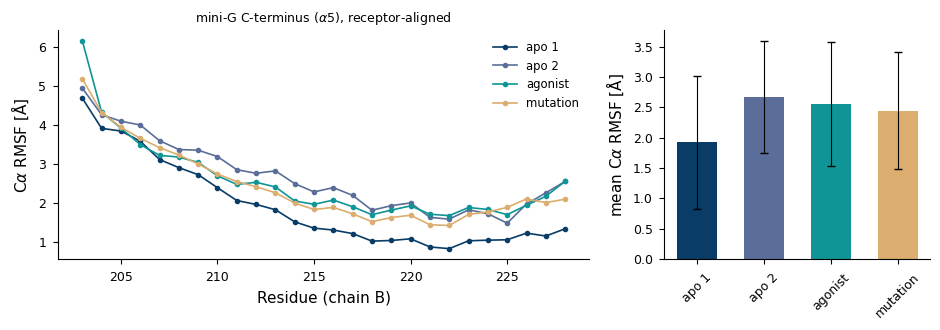

In [87]:
# align on the SAME receptor TM core as before (chain A)
core_sel = ("chainID A and name CA and "
            "(resid 42:66 77:101 118:144 158:180 210:234 255:285 296:319)")

# mini-G Cα C-terminus (α5), chain B
cterm = (203, 228)
gprot_sel = f"chainID B and name CA and resid {cterm[0]}:{cterm[1]}"

states = [('apo', 1, 'apo 1'),
          ('apo', 2, 'apo 2'),
          ('agonist', 1, 'agonist'),
          ('mutation', 1, 'mutation')]

palette = {'apo 1': '#093c66', 'apo 2': '#5a6e99',
           'agonist': '#0f9596', 'mutation': '#dbad6e'}

# ---- compute per-residue Cα RMSF of the mini-G C-terminus for each state ----
rmsf_data = {}   # label -> (resids, rmsf)
for system, state, label in states:
    base = f'{system}/macrostates_frames/{state}'
    ref = mda.Universe(f'{base}/7f9y-align.pdb')
    u = mda.Universe(f'{base}/7f9y-align.pdb', f'{base}/traj-align.xtc')

    # align ensemble on receptor core (in memory -> no file written)
    align.AlignTraj(u, ref, select=core_sel, in_memory=True).run()

    # RMSF of mini-G C-terminus, expressed in the receptor frame
    ca = u.select_atoms(gprot_sel)
    R = rms.RMSF(ca).run()
    rmsf_data[label] = (ca.resids.copy(), R.results.rmsf.copy())

# ---- summary: mean RMSF over the C-terminus per state ----
print(f"Mean Cα RMSF [Å] of mini-G C-terminus (chain B resid {cterm[0]}-{cterm[1]}), "
      f"receptor-aligned (± residue-to-residue SD):")
cterm_mean = {}
for label, (resids, rmsf) in rmsf_data.items():
    cterm_mean[label] = (rmsf.mean(), rmsf.std())
    print(f"  {label:<10} {rmsf.mean():.2f} ± {rmsf.std():.2f}")

# ---- plot ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.4),
                               gridspec_kw={'width_ratios': [2, 1]}, tight_layout=True)

# (a) per-residue RMSF profile along the C-terminus
for label, (resids, rmsf) in rmsf_data.items():
    ax1.plot(resids, rmsf, label=label, color=palette[label], lw=1.2, marker='o', ms=3)

ax1.legend(frameon=False, fontsize='small')
ax1.set_title(r'mini-G C-terminus ($\alpha$5), receptor-aligned', fontsize=9)
plot_adjust_settings('Residue (chain B)', r'C$\alpha$ RMSF [Å]', ax=ax1)

# (b) mean RMSF over the C-terminus, one bar per state
labels = [lab for _, _, lab in states]
means = [cterm_mean[l][0] for l in labels]
errs  = [cterm_mean[l][1] for l in labels]
bar_colors = [palette[l] for l in labels]
ax2.bar(labels, means, yerr=errs, capsize=3, color=bar_colors,
        error_kw=dict(elinewidth=0.8), width=0.6)
ax2.tick_params(axis='x', rotation=45)
plot_adjust_settings('', r'mean C$\alpha$ RMSF [Å]', ax=ax2)

sns.despine()
plt.show()

α5 Cα RMSD [Å] to equilibration pose (receptor-core superposed):
  apo 1      3.24 ± 1.25   (median 3.21)
  apo 2      6.67 ± 1.57   (median 6.89)
  agonist    4.44 ± 1.11   (median 4.43)
  mutation   2.93 ± 1.18   (median 2.41)


/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_96061/939475293.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='label', y='rmsd', order=order, palette=palette,


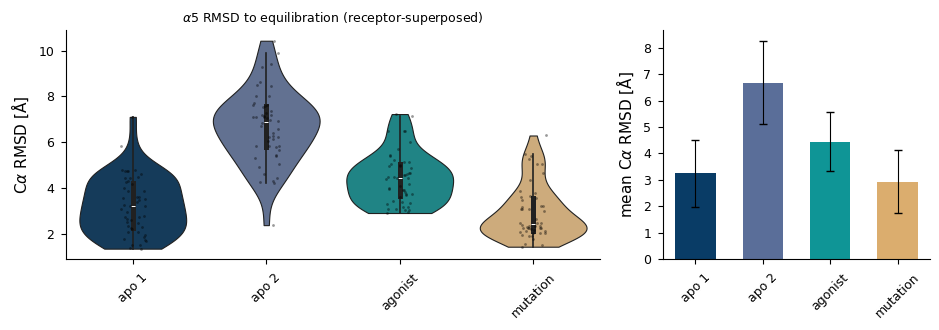

In [88]:
from MDAnalysis.analysis.align import rotation_matrix

# common reference = apo equilibration structure (Cα-only, valid for all systems)
REF_GRO = "/Volumes/LaCie/250107_msm_GHSR-miniG/apo/MD_input/step6.6_equilibration.gro"

core_ranges = [(42, 66), (77, 101), (118, 144), (158, 180),
               (210, 234), (255, 285), (296, 319)]
a5 = (203, 228)
core_sel = ("chainID A and name CA and "
            "(resid 42:66 77:101 118:144 158:180 210:234 255:285 296:319)")
a5_sel   = f"chainID B and name CA and resid {a5[0]}:{a5[1]}"

states = [('apo', 1, 'apo 1'),
          ('apo', 2, 'apo 2'),
          ('agonist', 1, 'agonist'),
          ('mutation', 1, 'mutation')]
palette = {'apo 1': '#093c66', 'apo 2': '#5a6e99',
           'agonist': '#0f9596', 'mutation': '#dbad6e'}

# reference protein Cα (receptor->mini-G order, 528); matches apo mobile order exactly
ref_u  = mda.Universe(REF_GRO)
ref_ca = ref_u.select_atoms("protein and name CA")

# locate core & α5 within that 528-CA order using the chain-aware apo mobile topology
apo_ca = mda.Universe("apo/macrostates_frames/1/7f9y-align.pdb").select_atoms("protein and name CA")
assert apo_ca.n_atoms == ref_ca.n_atoms, f"apo CA {apo_ca.n_atoms} != ref {ref_ca.n_atoms}"
ch, rs = apo_ca.chainIDs, apo_ca.resids
core_res  = np.logical_or.reduce([(rs >= lo) & (rs <= hi) for lo, hi in core_ranges])
core_mask = (ch == 'A') & core_res
a5_mask   = (ch == 'B') & (rs >= a5[0]) & (rs <= a5[1])

ref_core   = ref_ca.positions[core_mask]
ref_a5     = ref_ca.positions[a5_mask]
ref_com    = ref_core.mean(axis=0)
ref_core_c = ref_core - ref_com

rows = []
for system, state, label in states:
    base = f'{system}/macrostates_frames/{state}'
    u = mda.Universe(f'{base}/7f9y-align.pdb', f'{base}/traj-align.xtc')

    mob_core = u.select_atoms(core_sel)     # chain A only -> ignores agonist chain X
    mob_a5   = u.select_atoms(a5_sel)       # chain B α5
    assert mob_core.n_atoms == len(ref_core) and mob_a5.n_atoms == len(ref_a5), \
        f"{label}: core {mob_core.n_atoms}/{len(ref_core)}  a5 {mob_a5.n_atoms}/{len(ref_a5)}"

    for ts in u.trajectory:
        mc = mob_core.positions
        ma = mob_a5.positions
        mc_com = mc.mean(axis=0)
        R, _ = rotation_matrix(mc - mc_com, ref_core_c)     # fit receptor core -> ref core
        a5_fit = (ma - mc_com) @ R.T + ref_com              # apply same transform to α5
        rmsd = np.sqrt(((a5_fit - ref_a5) ** 2).sum(axis=1).mean())
        rows.append({'label': label, 'rmsd': rmsd})

df = pd.DataFrame(rows)

# ---- summary ----
order = [lab for _, _, lab in states]
print("α5 Cα RMSD [Å] to equilibration pose (receptor-core superposed):")
for label in order:
    v = df.loc[df['label'] == label, 'rmsd']
    print(f"  {label:<10} {v.mean():.2f} ± {v.std():.2f}   (median {v.median():.2f})")

# ---- plot ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.4),
                               gridspec_kw={'width_ratios': [2, 1]}, tight_layout=True)

sns.violinplot(data=df, x='label', y='rmsd', order=order, palette=palette,
               ax=ax1, inner='box', cut=0, linewidth=0.8)
sns.stripplot(data=df, x='label', y='rmsd', order=order, ax=ax1,
              color='black', size=2, alpha=0.4)
ax1.tick_params(axis='x', rotation=45)
ax1.set_title(r'$\alpha$5 RMSD to equilibration (receptor-superposed)', fontsize=9)
plot_adjust_settings('', r'C$\alpha$ RMSD [Å]', ax=ax1)

means = [df.loc[df['label'] == l, 'rmsd'].mean() for l in order]
errs  = [df.loc[df['label'] == l, 'rmsd'].std()  for l in order]
ax2.bar(order, means, yerr=errs, capsize=3, color=[palette[l] for l in order],
        error_kw=dict(elinewidth=0.8), width=0.6)
ax2.tick_params(axis='x', rotation=45)
plot_adjust_settings('', r'mean C$\alpha$ RMSD [Å]', ax=ax2)

sns.despine()
plt.show()

ICL2 Cα RMSD [Å] to equilibration pose (receptor-core superposed):
  apo 1      3.65 ± 0.70   (median 3.55)
  apo 2      6.28 ± 1.31   (median 6.28)
  agonist    5.39 ± 1.62   (median 5.28)
  mutation   3.62 ± 1.00   (median 3.76)


/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_96061/903486199.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='label', y='rmsd', order=order, palette=palette,


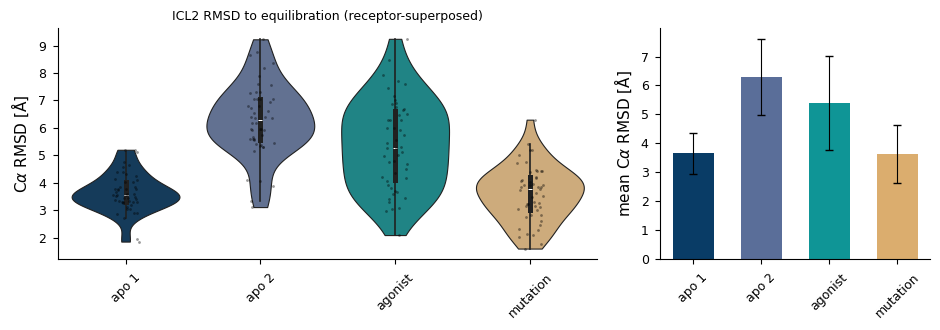

In [89]:
from MDAnalysis.analysis.align import rotation_matrix

# common reference = apo equilibration structure (Cα-only)
REF_GRO = "/Volumes/LaCie/250107_msm_GHSR-miniG/apo/MD_input/step6.6_equilibration.gro"

core_ranges = [(42, 66), (77, 101), (118, 144), (158, 180),
               (210, 234), (255, 285), (296, 319)]
icl2 = (146, 156)
core_sel = ("chainID A and name CA and "
            "(resid 42:66 77:101 118:144 158:180 210:234 255:285 296:319)")
icl2_sel = f"chainID A and name CA and resid {icl2[0]}:{icl2[1]}"

states = [('apo', 1, 'apo 1'),
          ('apo', 2, 'apo 2'),
          ('agonist', 1, 'agonist'),
          ('mutation', 1, 'mutation')]
palette = {'apo 1': '#093c66', 'apo 2': '#5a6e99',
           'agonist': '#0f9596', 'mutation': '#dbad6e'}

# reference protein Cα (receptor->mini-G order); matches apo mobile order exactly
ref_u  = mda.Universe(REF_GRO)
ref_ca = ref_u.select_atoms("protein and name CA")

# locate core & ICL2 within the reference CA order using the chain-aware apo mobile
apo_ca = mda.Universe("apo/macrostates_frames/1/7f9y-align.pdb").select_atoms("protein and name CA")
assert apo_ca.n_atoms == ref_ca.n_atoms, f"apo CA {apo_ca.n_atoms} != ref {ref_ca.n_atoms}"
ch, rs = apo_ca.chainIDs, apo_ca.resids
core_res   = np.logical_or.reduce([(rs >= lo) & (rs <= hi) for lo, hi in core_ranges])
core_mask  = (ch == 'A') & core_res
icl2_mask  = (ch == 'A') & (rs >= icl2[0]) & (rs <= icl2[1])

ref_core   = ref_ca.positions[core_mask]
ref_icl2   = ref_ca.positions[icl2_mask]
ref_com    = ref_core.mean(axis=0)
ref_core_c = ref_core - ref_com

rows = []
for system, state, label in states:
    base = f'{system}/macrostates_frames/{state}'
    u = mda.Universe(f'{base}/7f9y-align.pdb', f'{base}/traj-align.xtc')

    mob_core = u.select_atoms(core_sel)
    mob_icl2 = u.select_atoms(icl2_sel)
    assert mob_core.n_atoms == len(ref_core) and mob_icl2.n_atoms == len(ref_icl2), \
        f"{label}: core {mob_core.n_atoms}/{len(ref_core)}  icl2 {mob_icl2.n_atoms}/{len(ref_icl2)}"

    for ts in u.trajectory:
        mc = mob_core.positions
        ml = mob_icl2.positions
        mc_com = mc.mean(axis=0)
        R, _ = rotation_matrix(mc - mc_com, ref_core_c)     # fit receptor core -> ref core
        icl2_fit = (ml - mc_com) @ R.T + ref_com            # apply same transform to ICL2
        rmsd = np.sqrt(((icl2_fit - ref_icl2) ** 2).sum(axis=1).mean())
        rows.append({'label': label, 'rmsd': rmsd})

df = pd.DataFrame(rows)

# ---- summary ----
order = [lab for _, _, lab in states]
print("ICL2 Cα RMSD [Å] to equilibration pose (receptor-core superposed):")
for label in order:
    v = df.loc[df['label'] == label, 'rmsd']
    print(f"  {label:<10} {v.mean():.2f} ± {v.std():.2f}   (median {v.median():.2f})")

# ---- plot ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.4),
                               gridspec_kw={'width_ratios': [2, 1]}, tight_layout=True)

sns.violinplot(data=df, x='label', y='rmsd', order=order, palette=palette,
               ax=ax1, inner='box', cut=0, linewidth=0.8)
sns.stripplot(data=df, x='label', y='rmsd', order=order, ax=ax1,
              color='black', size=2, alpha=0.4)
ax1.tick_params(axis='x', rotation=45)
ax1.set_title('ICL2 RMSD to equilibration (receptor-superposed)', fontsize=9)
plot_adjust_settings('', r'C$\alpha$ RMSD [Å]', ax=ax1)

means = [df.loc[df['label'] == l, 'rmsd'].mean() for l in order]
errs  = [df.loc[df['label'] == l, 'rmsd'].std()  for l in order]
ax2.bar(order, means, yerr=errs, capsize=3, color=[palette[l] for l in order],
        error_kw=dict(elinewidth=0.8), width=0.6)
ax2.tick_params(axis='x', rotation=45)
plot_adjust_settings('', r'mean C$\alpha$ RMSD [Å]', ax=ax2)

sns.despine()
plt.show()